Lander Dirix

## Overzicht
* 1. Data en imports
* 2. EDA
    * 2.1 Overzicht van de dataset
    * 2.2 Nummers per artiest en album
    * 2.3 Kolomtypes
    * 2.4 Opschonen van kolommen
    * 2.5 Sortering en groepering
    * 2.6 Kwaliteit van de data
    * 2.7 Doelveld
* 3. Splitsen en afbakening van het probleem
    * 3.1 Splitsen in train, validatie en test
    * 3.2 Snelle test op alle genres
    * 3.3 Groepering van genres
* 4. Verdiepende EDA
    * 4.1 Histogrammen per feature
    * 4.2 Profiel per genrefamilie
    * 4.3 Correlatiematrix
* 5. Preprocessing
* 6. Modellen en hyperparameter tuning
* 7. Evaluatie van het beste model
    * 7.1 Vergelijking met baselines
    * 7.2 Prestaties per genrefamilie
    * 7.3 Wat is het probleem bij pop-mix?
* 8. Verbeterpogingen
    * 8.1 Pop-mix opsplitsen
    * 8.2 Trainen met gebalanceerde klassen
* 9. Featureselectie
* 10. Eindevaluatie op de testset
* 11. Eindconclusie

# 1. Data en imports

In [109]:
import pandas as pd
import seaborn as sn
import numpy as np
import matplotlib.pyplot as plt
import os
import time

In [110]:
original_df = pd.read_csv("./Spotify_tracks_final.csv")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
pd.set_option("display.float_format", "{:.3f}".format)

In [111]:
RANDOM_STATE = 1

In [112]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from scipy.stats import loguniform, randint
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, top_k_accuracy_score, classification_report, confusion_matrix)
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance

# 2. EDA

## 2.1 Overzicht van de dataset

In [113]:
n_rows, n_cols = original_df.shape
print(f"Rijen: {n_rows:,}")
print(f"Kolommen: {n_cols}")
print(f"Bestandsgrootte: {os.path.getsize('./Spotify_tracks_final.csv') / 1e9:.2f} GB")
print(f"Geheugengebruik: {original_df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Rijen: 2,112,746
Kolommen: 30
Bestandsgrootte: 0.82 GB
Geheugengebruik: 2.01 GB


In [114]:
original_df.head(10)

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71c...,ambient,0.990,0.184,0.033,0.877,1,0.100,-28.184,0,0.037,168.133,3,0.035,0,265.653,4.428
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9...,ambient,0.985,0.250,0.015,0.971,5,0.067,-30.646,1,0.037,136.864,5,0.039,0,349.120,5.819
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd...,ambient,0.993,0.269,0.021,0.883,5,0.139,-24.620,0,0.040,69.487,4,0.041,0,128.039,2.134
3,3,The Heart Askes Pleasure First - The...,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da...,ambient,0.995,0.230,0.138,0.885,4,0.101,-19.591,0,0.037,165.197,3,0.171,0,190.960,3.183
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979...,ambient,0.995,0.611,0.002,0.967,7,0.082,-37.782,1,0.286,134.237,3,0.508,0,338.933,5.649
5,5,Comptine d'un autre été - Le fabuleu...,36xrCDskORciDQupSJdoQ0,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,141133,False,https://p.scdn.co/mp3-preview/926917...,ambient,0.968,0.391,0.111,0.933,7,0.099,-21.655,1,0.042,103.047,4,0.079,0,141.133,2.352
6,6,Someone To Watch Over Me,5RcvlmVx2xtFcp2Ta5pw7X,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,54,196666,False,NaN,blues,0.990,0.354,0.085,0.000,7,0.123,-13.738,1,0.035,97.684,1,0.197,1,196.666,3.278
7,7,I've Got A Crush On You,5DIVWgTeJ2fPIxaY9e7ZKn,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,53,196440,False,NaN,blues,0.986,0.455,0.106,0.000,2,0.122,-14.086,1,0.042,66.807,4,0.258,1,196.440,3.274
8,8,But Not For Me,65Dm4aRthohlvuuyKVydIu,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,23,195133,False,NaN,blues,0.986,0.410,0.098,0.000,4,0.174,-14.359,0,0.032,136.431,3,0.240,1,195.133,3.252
9,9,How Long Has This Been Going On?,0HEU3berJ5OBojU8XmEk1c,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,23,197666,False,NaN,blues,0.974,0.303,0.175,0.000,1,0.105,-14.203,0,0.038,168.743,4,0.250,1,197.666,3.294


In [115]:
cols = ["track_id", "album_id", "artist_id", "genre"]
display(original_df[cols].nunique().to_frame("aantal"))

,aantal
track_id,2112746
album_id,464281
artist_id,77854
genre,113


**Conclusie**

De dataset bevat 30 kolommen en meer dan 2,1 miljoen nummers, verdeeld over meer dan 464 duizend albums, bijna 78 duizend artiesten en 113 genres.

Het bestand is 0,82GB groot en neemt 2GB RAM in beslag. Daarom maken we zo weinig mogelijk kopieën en laten we ongebruikte kolommen vroeg vallen.


* **Multiklasse-probleem met vele klassen:** 
Met 113 genres haalt een model dat willekeurig gokt 1/113 = 0,9% accuracy. De echte baseline bepalen we na de analyse van de genreverdeling.
Omdat genres inhoudelijk vaak overlappen, is verwarring te verwachten. Daarom beslissen we later of we alle genres houden, de minst voorkomende genres laten vallen of verwante genres samenvoegen.


* **Groepering in de data:**
De eerste rijen zijn nummers van dezelfde artiest en hetzelfde album met hetzelfde genre. Een willekeurige split zou dus leakage kunnen veroorzaken. Dit onderzoeken we verder bij de verdeling per artiest en album en bepaalt hoe we de data splitsen.


## 2.2 Nummers per artiest en album

In [116]:
per_artiest = original_df.groupby("artist_id").size()
per_album = original_df.groupby("album_id").size()

pd.DataFrame({
    "nummers per artiest": per_artiest.describe(percentiles=[.5, .9, .99]),
    "nummers per album": per_album.describe(percentiles=[.5, .9, .99]),
})


,nummers per artiest,nummers per album
count,77854.000,464281.000
mean,27.137,4.551
std,93.772,5.494
min,1.000,1.000
50%,8.000,2.000
90%,67.000,11.000
99%,256.000,22.000
max,10035.000,315.000


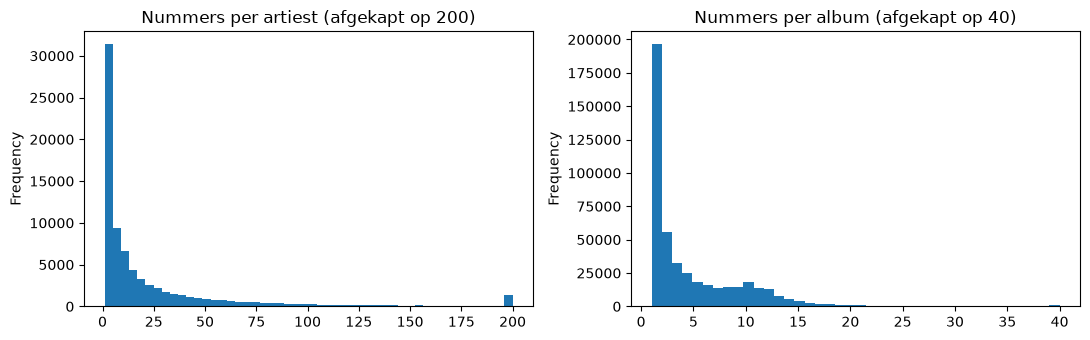

In [117]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
per_artiest.clip(upper=200).plot.hist(bins=50, ax=axes[0], title="Nummers per artiest (afgekapt op 200)")
per_album.clip(upper=40).plot.hist(bins=40, ax=axes[1], title="Nummers per album (afgekapt op 40)")
plt.tight_layout(); plt.show()

In [118]:
top_10 = per_artiest.sort_values(ascending=False).head(10)
display(original_df.drop_duplicates("artist_id").set_index("artist_id")
        .loc[top_10.index, ["artist_name"]].assign(n_nummers=top_10))

,artist_name,n_nummers
artist_id,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,10035
1U5zgr455OGyIkLNXvDdrf,Traditional,8737
4NJhFmfw43RLBLjQvxDuRS,Wolfgang Amadeus Mozart,6316
1JOQXgYdQV2yfrhewqx96o,Giuseppe Verdi,6104
5as8A4G47Ohu9NSWs3Je8U,Asha Bhosle,5492
61JrslREXq98hurYL2hYoc,Lata Mangeshkar,4214
1C1x4MVkql8AiABuTw6DgE,Richard Wagner,3935
2wOqMjp9TyABvtHdOSOTUS,Ludwig van Beethoven,3558
0roWUeP7Ac4yK4VN6L2gF4,Gioachino Rossini,3487


In [119]:
top1_procent = per_artiest.nlargest(int(len(per_artiest) * 0.01)).sum() / n_rows
print(f"Top 1% van de artiesten bevat {top1_procent:.1%} van alle nummers")
print(f"Grootste artiest: {per_artiest.max() / n_rows:.2%} van alle nummers")

Top 1% van de artiesten bevat 19.4% van alle nummers
Grootste artiest: 0.47% van alle nummers


**Conclusie**

Beide verdelingen zijn sterk rechtsscheef.
De mediaan is 8 nummers per artiest en 2 per album, terwijl het gemiddelde veel hoger ligt (27,1 en 4,6). 
De top 1% van artiesten levert bijna 20% van alle nummers.

De grootste artiesten zijn vooral klassieke componisten (zoals Bach met meer dan 10 duizend nummers).
Dit is waarschijnlijk omdat de artiest vaak de componist is, in plaats van de uitvoerder.
"Traditional" is geen echte artiest maar een verzamelnaam voor onbekende uitvoerders.

* **Groepssplit:** 
Nummers van dezelfde artiest blijven samen in een split. De grootste artiest is ongeveer 0,5% van de data, dus er zouden geen folds mogen zijn die door één artiest is gedomineerd.

* **Verzamelnamen:** 
"Traditional" zal volledig in één split terecht komen. Dat is geen leakage, maar die nummers zijn onderling niet representatief voor één artiest.

* **Nog te controleren:** 
Bestaan zeldzame genres grotendeels uit één artiest, want dan wordt stratificatie moeilijk. Dat bekijken we bij de genreverdeling.

## 2.3 Kolomtypes

In [120]:
print(original_df.dtypes.value_counts())
original_df.dtypes.to_frame("aantal kolommen")

str        11
float64    11
int64       7
bool        1
Name: count, dtype: int64


,aantal kolommen
Unnamed: 0,int64
track_name,str
track_id,str
album_name,str
album_id,str
album_image,str
album_release_date,str
album_release_date_precision,str
artist_name,str
artist_id,str


De dataset bevat 11 tekstkolommen, 11 float-kolommen, 7 int-kolommen en 1 booleaanse kolom. 

Het type zegt niet altijd wat een kolom betekent: kolommen als key, mode en time_signature staan als integer, maar zijn categorisch.

## 2.4 Opschonen van kolommen

In [121]:
# Unnamed: 0 = achtergebleven csv-index?
print("Unnamed: 0 == rij-index:", (original_df["Unnamed: 0"] == original_df.index).all())

print("min:", original_df["Unnamed: 0"].min(), "| max:", original_df["Unnamed: 0"].max(), )

# Duur: drie eenheden voor dezelfde grootheid?
print("seconden == ms / 1000:", np.allclose(original_df["duration_seconds"], original_df["duration_ms"] / 1000))
print("minuten == ms / 60000:", np.allclose(original_df["duration_minutes"], original_df["duration_ms"] / 60000))

Unnamed: 0 == rij-index: False
min: 0 | max: 3924134
seconden == ms / 1000: True
minuten == ms / 60000: True


In [122]:
# database_shard_id: hangt hij samen met jaar of genre?
jaar = original_df["album_release_date"].str[:4].astype(int)
display(original_df.assign(jaar=jaar).groupby("database_shard_id")
        .agg(n=("track_id", "size"), jaar_mediaan=("jaar", "median"),
             n_genres=("genre", "nunique"),
             top_genres=("genre", lambda s: ", ".join(s.value_counts().head(3).index))))

,n,jaar_mediaan,n_genres,top_genres
database_shard_id,,,,
0,30245,2004.000,110,"ambient, indian, classical"
1,44343,1986.000,108,"blues, indian, french"
2,37431,1996.000,109,"british, folk, acoustic"
3,25312,2005.000,110,"children, german, indian"
4,46704,1984.000,106,"classical, blues, french"
...,...,...,...,...
108,9890,2012.000,112,"progressive-house, classical, disco"
109,10115,2014.000,111,"hardstyle, classical, german"
110,5706,2010.000,110,"dubstep, german, indian"


In [123]:
# artist_id versus artist_name
namen_per_id = original_df.groupby("artist_id")["artist_name"].nunique()
ids_per_naam = original_df.groupby("artist_name")["artist_id"].nunique()
print("artist_id's met >1 naam:", (namen_per_id > 1).sum())
print("artist_name's met >1 id:", (ids_per_naam > 1).sum())

artist_id's met >1 naam: 0
artist_name's met >1 id: 420


In [124]:
namen = ids_per_naam[ids_per_naam > 1].index
sub = original_df[original_df["artist_name"].isin(namen)]

# per (naam, id): de top-3 genres als tekst
genres = (sub.groupby(["artist_name", "artist_id"])["genre"]
             .agg(lambda s: ", ".join(s.value_counts().head(3).index)))

# per naam: de genres van twee id's naast elkaar
paren = genres.groupby("artist_name").apply(lambda s: list(s)[:2])
tabel = pd.DataFrame(paren.tolist(), index=paren.index, columns=["genres_id1", "genres_id2"])

tabel.sample(25, random_state=42)

,genres_id1,genres_id2
artist_name,,
Germ,emo,black-metal
Shining,metal,black-metal
John Wayne,brazil,dancehall
The Controllers,punk,soul
Zola,k-pop,french
Camarão,forro,forro
Felix Martin,jazz,show-tunes
Franco,malay,gospel
Anomalie,jazz,black-metal


**artist_id versus artist_name.** Elke `artist_id` hoort bij precies één naam, maar 420 namen komen voor onder meer dan één id (0,5%). Meestal hebben naam-genoten totaal andere genres, wat erop duidt dat het verschillende artiesten zijn die toevallig dezelfde naam hebben. 

Soms is het wel dezelfde artiest met twee profielen (zoals Cafe Jazz Deluxe met jazz of Yosef Moshe Kahana met j-pop). In dit geval is het gevaarlijker voor de split. Dezelfde artiest zou in train en test kunnen zijn. Groeperen op naam vangt dit op en het samen houden van naamgenoten kost niets. Daarom groeperen we op naam in plaats van ID.

**Welke kolommen laten we vallen en welke houden we?**

| Kolom | Beslissing | Reden |
|---|---|---|
| `Unnamed: 0` | Droppen | Achtergebleven index van een groter origineel CSV-bestand: de waarden zijn uniek en stijgend maar lopen op tot 3,9 miljoen, terwijl de dataset maar 2,1 miljoen rijen bevat |
| `track_id`, `album_id`, `artist_id` | Droppen | Identifiers zonder muzikale informatie |
| `album_image`, `preview_url` | Droppen | Urls |
| `database_shard_id` | Droppen | Technische id van de database waarin het record zat. Elke shard bevat rond de 110 van de 113 genres, dus de shard zegt niets over het genre. |
| `duration_ms`, `duration_minutes` | Droppen | Redundant: dezelfde informatie als `duration_seconds` |
| `track_name`, `album_name` | Niet in het hoofdmodel, apart tekstexperiment | Vrije tekst die eerst verwerkt moet worden bevat mogelijk sterke signalen (taal, "Op. 67", "Remix"), maar albumnamen van compilaties noemen vaak letterlijk het genre. Dit kan als uitbreiding onderzocht worden |
| `album_release_date`, `album_release_date_precision` | Droppen na extractie | Gemengde formaten (jaar, jaar-maand, volledige datum). Betrouwbaarheid moet onderzocht worden |
| `artist_name` | Houden, enkel om te groeperen | Wordt geen feature, wel nodig voor de groepssplit |
| `genre` | Houden | Doelveld |
| `duration_seconds` | Houden | Eén kolom voor duration overhouden |
| `release_year` | Houden | Het uitgelezen jaar uit album_release_date |
| `popularity`, `explicit` | Voorlopig houden | Metadata, geen eigenschap van het geluid. Beslissing over gebruik volgt bij de featureselectie |
| `acousticness`, `danceability`, `energy`, `instrumentalness`, `liveness`, `loudness`, `speechiness`, `tempo`, `valence`, `key`, `mode`, `time_signature` | Houden | audiofeatures |

In [125]:
keep = ["artist_name", "genre", "duration_seconds", "popularity", "explicit",
        "acousticness", "danceability", "energy", "instrumentalness", "liveness",
        "loudness", "speechiness", "tempo", "valence", "key", "mode", "time_signature"]

df = original_df[keep].copy()

print(df.shape)
print(f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

df.head()

(2112746, 17)
0.49 GB


,artist_name,genre,duration_seconds,popularity,explicit,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,key,mode,time_signature
0,Jeroen van Veen,ambient,265.653,2,False,0.990,0.184,0.033,0.877,0.100,-28.184,0.037,168.133,0.035,1,0,3
1,Jeroen van Veen,ambient,349.120,0,False,0.985,0.250,0.015,0.971,0.067,-30.646,0.037,136.864,0.039,5,1,5
2,Jeroen van Veen,ambient,128.039,1,False,0.993,0.269,0.021,0.883,0.139,-24.620,0.040,69.487,0.041,5,0,4
3,Jeroen van Veen,ambient,190.960,0,False,0.995,0.230,0.138,0.885,0.101,-19.591,0.037,165.197,0.171,4,0,3
4,Jeroen van Veen,ambient,338.933,4,False,0.995,0.611,0.002,0.967,0.082,-37.782,0.286,134.237,0.508,7,1,3


## 2.5 Sortering en groepering

Volledig gesorteerd op jaar: False


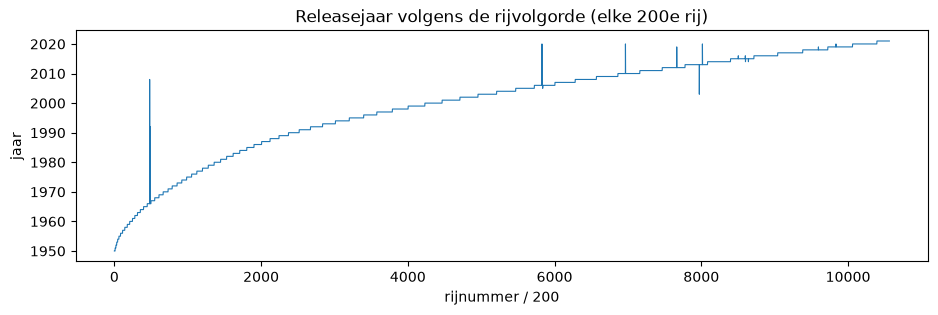

Rijen waar het jaar daalt t.o.v. de vorige rij: 930 van 2,112,746
Aantal aaneengesloten blokken met hetzelfde genre: 6,083


In [126]:
jaar = original_df["album_release_date"].str[:4].astype(int)
print("Volledig gesorteerd op jaar:", jaar.is_monotonic_increasing)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(jaar.values[::200], lw=.8)
ax.set(title="Releasejaar volgens de rijvolgorde (elke 200e rij)", xlabel="rijnummer / 200", ylabel="jaar")
plt.show()

print(f"Rijen waar het jaar daalt t.o.v. de vorige rij: {(jaar.diff() < 0).sum()} van {n_rows:,}")
print(f"Aantal aaneengesloten blokken met hetzelfde genre: {(original_df['genre'] != original_df['genre'].shift()).sum():,}")


**Conclusie**

De rijen staan (op 930 uitzonderingen na) gesorteerd op releasejaar, en binnen een jaar in ongeveer 6000 blokken van hetzelfde genre (met gemiddeld 350 rijen per blok). Elke combinatie van jaar en genre staat dus in precies één blok.

* **Nooit splitsen op rijvolgorde:** De eerste 80% als trainset nemen is een split op tijd, met oude muziek in train en recente muziek in test. De genreverdeling zou dan ook sterk verschillen tussen train en test. We splitsen dus nooit op positie.

* **Groepering op artiest:** Nummers van dezelfde artiest en hetzelfde album staan naast elkaar. Een willekeurige split zou ze over train en test verdelen. We groeperen daarom op artiest.

## 2.6 Kwaliteit van de data

### Duplicaten

In [127]:
# Rijen waarvan track_id meer dan 1x voorkomt
dup_track = original_df["track_id"].duplicated(keep=False)
print("Rijen waarvan track_id meer dan 1x voorkomt:", dup_track.sum(),
      f"({dup_track.mean():.1%})")

Rijen waarvan track_id meer dan 1x voorkomt: 0 (0.0%)


In [128]:
# Nummers met dezelfde titel en artiest
dup = original_df.duplicated(subset=["artist_name", "track_name"], keep=False)
print(f"Nummers met zelfde titel en artiest: {dup.sum():,} ({dup.mean():.1%})")

Nummers met zelfde titel en artiest: 0 (0.0%)


In [129]:
# Dezelfde opname onder een andere titel of artiest met identieke audiofeatures en duratie
audio = ["acousticness", "danceability", "energy", "instrumentalness", "liveness", "loudness",
         "speechiness", "tempo", "valence", "key", "mode", "time_signature", "duration_ms"]

dup_audio = original_df.duplicated(subset=audio, keep=False)
print(f"Rijen met identieke audiofeatures: {dup_audio.sum()} ({dup_audio.mean():.1%})")

genres_per_groep = original_df[dup_audio].groupby(audio)["genre"].nunique()
print(f"Groepen met duplicaten: {len(genres_per_groep)}, waarvan met tegenstrijdig genre: {(genres_per_groep > 1).sum()}")

col = audio + ["track_name", "artist_name", "genre"]
eerste = original_df.loc[dup_audio, col].drop_duplicates(audio)
tweede = original_df.loc[original_df.duplicated(audio), col].drop_duplicates(audio)
display(eerste.merge(tweede, on=audio, suffixes=("_1", "_2")).drop(columns=audio).head(10))

Rijen met identieke audiofeatures: 28200 (1.3%)
Groepen met duplicaten: 13134, waarvan met tegenstrijdig genre: 1827


,track_name_1,artist_name_1,genre_1,track_name_2,artist_name_2,genre_2
0,"Die Zauberflöte, K. 620: Ein Mädchen...",Wolfgang Amadeus Mozart,classical,"Die Zauberflöte, K. 620, Act II: ""Ei...",Wolfgang Amadeus Mozart,classical
1,"Warnung, K. 433/416C: Männer suchen ...",Wolfgang Amadeus Mozart,classical,"Warnung, K. 433/416C: Männer suchen ...",Staatskapelle Dresden,classical
2,"Le nozze di Figaro, K. 492: Overture",Wolfgang Amadeus Mozart,classical,"Die Entführung aus dem Serail, K. 38...",Staatskapelle Dresden,classical
3,Dharti Hamari Pe Tu Nit Nit,Surinder Kaur,folk,Dil Hai Lagane Ke Liye,Shamshad Begum,pop
4,Konialis,Stathis Koukoularis,folk,Konialis Dosekanisiakos,Stathis Koukoularis,folk
5,Eho Meinei o Ftohos,Stelios Kazantzidis,pop,Den zontaneuoun oi nekroi,Stelios Kazantzidis,pop
6,Give Mother My Crown,Lester Flatt,bluegrass,Give Mother My Crown (with The Foggy...,Flatt & Scruggs,bluegrass
7,Rhapsody for Cello and Piano No. 1,Béla Bartók,classical,Rhapsody for Cello and Piano No. 1: ...,Béla Bartók,classical
8,"Symphony No. 3 in F Major, Op. 90: I...",Johannes Brahms,classical,III. Poco allegretto,Johannes Brahms,german
9,"Ae Mere Dil Kahin Aur Chal, Pt. 2",Lata Mangeshkar,pop,"Ae Mere Dil Kahin Aur Chal, Pt. 1",Lata Mangeshkar,pop


**Conclusie**

`track_id` is uniek en er bestaat geen enkel paar met dezelfde titel en artiest. 

Toch hebben 1,3% van de rijen exact dezelfde audiofeatures als een andere rij. Het gaat om dezelfde opname onder een licht andere titel of artiestnaam. In 1827 groepen heeft dezelfde opname zelfs verschillende genres.

* **Leakage:** Als de kopieën bij een andere artiestnaam horen, kunnen ze in train en test terechtkomen. Het model wordt dan getest op een nummer dat het al gezien heeft.
* **Labelruis:** Exact dezelfde input met een ander genre kan nooit juist voorspeld worden.

**Beslissing:** we houden per groep met dezelfde features enkel de eerste rij. De data is op jaar gesorteerd, dus het eerste record is waarschijnlijk het origineel.

In [130]:
first_copy = ~original_df.duplicated(subset=audio)
n_voor = len(df)
df = df[first_copy]
print(f"Duplicaten: {n_voor} -> {len(df)} rijen ({n_voor - len(df)} verwijderd)")


Duplicaten: 2112746 -> 2097680 rijen (15066 verwijderd)


### Ontbrekende waarden

In [131]:
# Kolommen met ontbrekende waarden
na = original_df.isna().sum()
display(na[na > 0].to_frame("ontbrekend").assign(procent=lambda t: t["ontbrekend"] / n_rows * 100))
print(f"popularity == 0: {(original_df['popularity'] == 0).mean():.1%}")

,ontbrekend,procent
track_name,6,0.000
album_name,6,0.000
album_image,491,0.023
artist_name,17,0.001
preview_url,325237,15.394


popularity == 0: 20.2%


**Conclusie**

Er ontbreken enkel waarden in tekstkolommen. `preview_url` en `album_image` laten we toch al vallen. 
De 17 rijen zonder `artist_name` kunnen we niet groeperen bij het splitsen, dus worden ze verwijderd.

20% van de nummers heeft `popularity` 0. Dat is geen ontbrekende waarde maar een nummer dat bijna niet beluisterd wordt.

In [132]:
n_voor = len(df)
df = df[df["artist_name"].notna()]
print(f"Zonder artiest: {n_voor} -> {len(df)} rijen ({n_voor - len(df)} verwijderd)")

Zonder artiest: 2097680 -> 2097663 rijen (17 verwijderd)


### Onmogelijke waarden en outliers

In [133]:
checks = {
    "tempo == 0": original_df["tempo"] == 0,
    "time_signature == 0": original_df["time_signature"] == 0,
    "duration < 10 sec": original_df["duration_seconds"] < 10,
    "duration < 30 sec": original_df["duration_seconds"] < 30,
    "duration > 20 min": original_df["duration_seconds"] > 20 * 60,
}
display(pd.DataFrame({
    "aantal": {k: v.sum() for k, v in checks.items()},
    "procent": {k: v.mean() * 100 for k, v in checks.items()},
    "top-3 genres": {k: ", ".join(original_df.loc[v, "genre"].value_counts().head(3).index) for k, v in checks.items()},
}))

,aantal,procent,top-3 genres
tempo == 0,2,0.000,sleep
time_signature == 0,64,0.003,"opera, classical, sleep"
duration < 10 sec,1,0.000,indian
duration < 30 sec,3640,0.172,"grindcore, german, comedy"
duration > 20 min,5071,0.240,"indian, ambient, sleep"


**Conclusie**

Een tempo van 0 BPM of een time_signature van 0 (64 rijen) zijn onmogelijk. Deze rijen verwijderen we.

Heel lange nummers zijn mogelijk (zoals een opera-akte of een uur regengeluid). Deze waarden zijn juist informatief voor het genre en houden we.

In [134]:
n_voor = len(df)
df = df[(df["tempo"] > 0) & (df["time_signature"] > 0)]
print(f"Onmogelijke waarden: {n_voor} -> {len(df)} rijen ({n_voor - len(df)} verwijderd)")

Onmogelijke waarden: 2097663 -> 2097600 rijen (63 verwijderd)


### Releasedatums

album_release_date_precision
day      1739350
year      369943
month       3453
Name: count, dtype: int64

'day'-datums die op 1 januari vallen: 18.8%
Jaren: 1950 - 2021


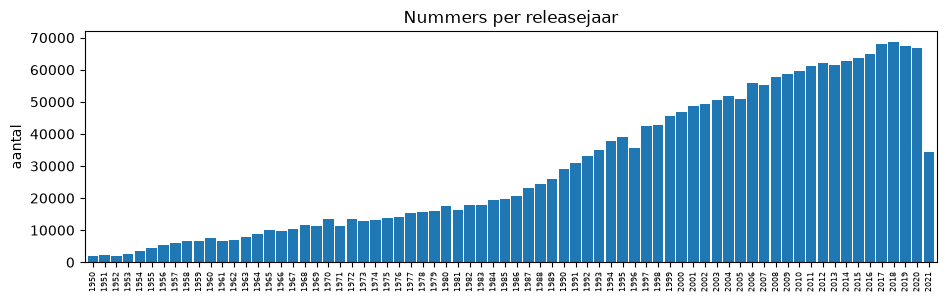

In [135]:
precisie = original_df["album_release_date_precision"]
print(precisie.value_counts())

jaar = original_df["album_release_date"].str[:4].astype(int)

print(f"\n'day'-datums die op 1 januari vallen: {original_df.loc[precisie == "day", 'album_release_date'].str.endswith('-01-01').mean():.1%}")
print(f"Jaren: {jaar.min()} - {jaar.max()}")

fig, ax = plt.subplots(figsize=(11, 3))
jaar.value_counts().sort_index().plot.bar(ax=ax, width=.9)
ax.set(title="Nummers per releasejaar", xlabel="", ylabel="aantal")
ax.tick_params(axis="x", labelsize=6)
plt.show()

**Conclusie**

De datum heeft drie formaten (jaar, jaar-maand en volledige datum). Van de volledige datums valt 18,8% op 1 januari. De echte datum is waarschijnlijk niet gekend. Enkel het jaar is dus betrouwbaar, en daarom houden we alleen `release_year`.

Ook het jaar is ruis: het is de datum van het album. Een compilatie of heruitgave krijgt het jaar van de heruitgave. `release_year` zegt dus iets over wanneer het album uitkwam, niet altijd over het tijdperk van de muziek. 

De eerste nummers in de dataset zijn van 1950, dit kan erop wijzen dat de dataset vooraf gefilterd werd.

In [136]:
df["release_year"] = original_df["album_release_date"].str[:4].astype(int)

## 2.7 Doelveld

### Aantal genres en verdeling

In [137]:
genre_counts = df["genre"].value_counts()
genre_counts.describe()

count     113.000
mean    18562.832
std     10537.146
min        66.000
25%     10128.000
50%     17569.000
75%     25213.000
max     47973.000
Name: count, dtype: float64

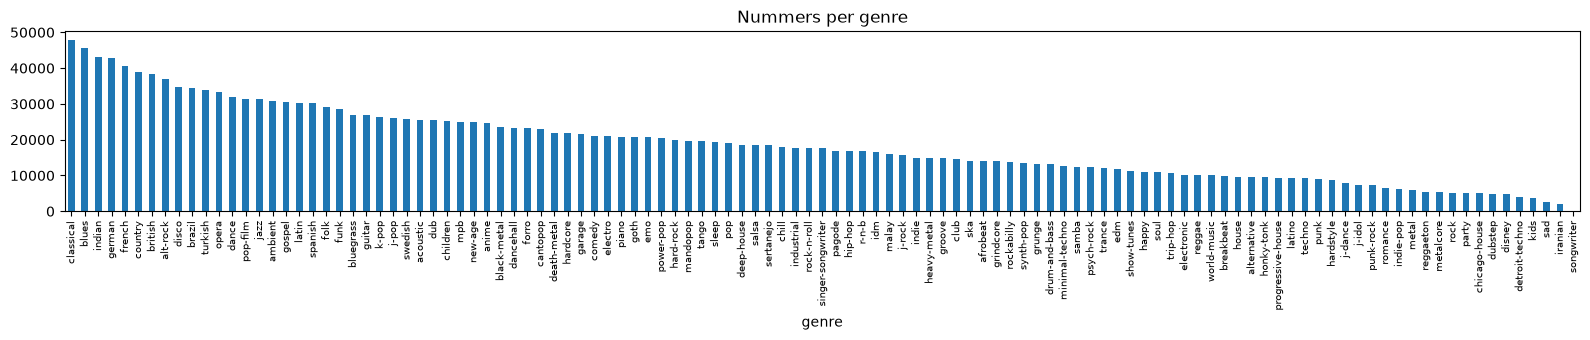

In [138]:
fig, ax = plt.subplots(figsize=(16, 3.5))
genre_counts.plot.bar(ax=ax, title="Nummers per genre")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

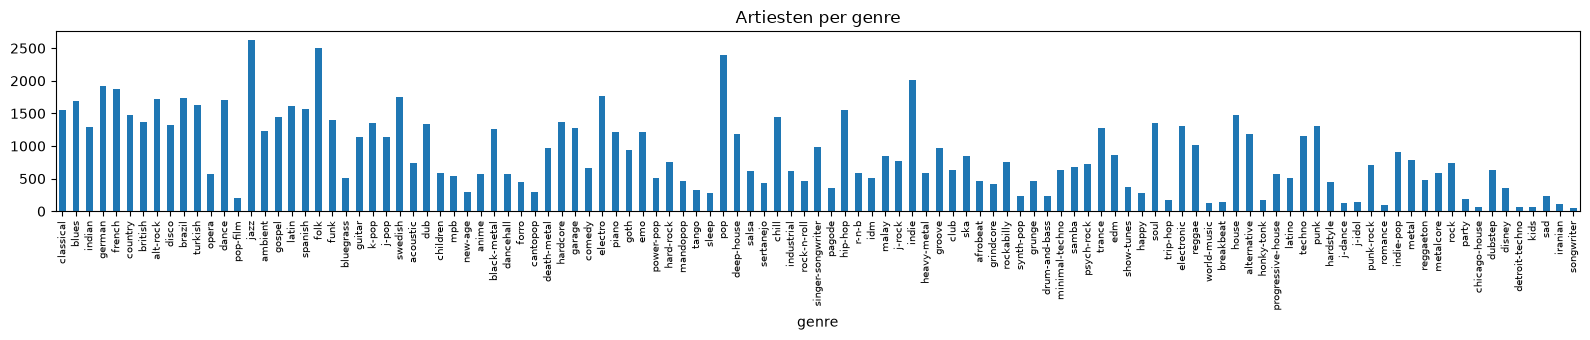

In [139]:
artiesten_per_genre = df.groupby("genre")["artist_name"].nunique()

fig, ax = plt.subplots(figsize=(16, 3.5))
artiesten_per_genre[genre_counts.index].plot.bar(ax=ax, title="Artiesten per genre")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

**Conclusie**

De 113 genres zijn redelijk gebalanceerd: de meeste hebben tussen 10 en 45 duizend nummers. Enkel songwriter is een uitschieter met minder dan 100 nummers. 

Het aantal artiesten per genre verschilt veel meer: sommige genres steunen op minder dan 100 artiesten. Een model ziet daar dus weinig verschillende "stemmen" en riskeert de stijl van die paar artiesten te leren in plaats van het genre.

Belangrijker is wat de genres zijn. Ze zijn niet allemaal muzikale stijlen:

* **Taal of regio:** indian, german, french, british, ...
* **Stemming of gelegenheid:** happy, sad, romance, ...
* **Doelpubliek of medium:** children, disney, anime, show-tunes, ...
* **Instrument of vaag:** guitar, garage, world-music, ...

Deze labels zijn vaak niet te voorspellen uit audiofeatures, of ze overlappen volledig met andere genres.

### Genres per artiest en album

In [140]:
genres_per_artiest = df.groupby("artist_name")["genre"].nunique()
print(f"Artiesten met >1 genre: {(genres_per_artiest > 1).mean():.1%}")

telling = df.groupby(["artist_name", "genre"]).size()
print(f"Nummers in het meest voorkomende genre van hun artiest: {telling.groupby(level=0).max().sum() / len(df):.1%}")

genres_per_album = original_df.loc[df.index].groupby("album_id")["genre"].nunique()
print(f"Albums met >1 genre: {(genres_per_album > 1).mean():.1%}")

Artiesten met >1 genre: 20.4%
Nummers in het meest voorkomende genre van hun artiest: 88.6%
Albums met >1 genre: 11.8%


**Conclusie**

80% van de artiesten heeft maar één genre, en bijna 90% van de nummers heeft het meest voorkomende genre van hun artiest. Het genre is dus grotendeels een eigenschap van de artiest, niet van het nummer.

* **Gevolg voor de split:** Dit bevestigt de keuze om te groeperen op artiest. Anders kan een model de artiest herkennen in plaats van het genre, en is de testscore te optimistisch.

* **Labelruis:** 12% van de albums heeft nummers met verschillende genres, terwijl ze meestal hetzelfde klinken. Het genre volgt dus niet altijd uit de muziek, wat de  haalbare accuracy beperkt.

# 3. Splitsen en afbakening van het probleem

## 3.1 Splitsen in train, validatie en test


In [141]:
# Test = 20%
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rest_idx, test_idx = next(sgkf.split(df, df["genre"], groups=df["artist_name"]))
rest_df, test_df = df.iloc[rest_idx], df.iloc[test_idx]

# Validatie = 20% (1/4e van rest), train = 60% (3/4e van rest)
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
train_idx, val_idx = next(sgkf.split(rest_df, rest_df["genre"], groups=rest_df["artist_name"]))
train_df, val_df = rest_df.iloc[train_idx], rest_df.iloc[val_idx]
del rest_df

We splitsen de data via de eerder besproken aanpak:
* **Gegroepeerd op `artist_name`:** alle nummers van een artiest zitten in dezelfde split, zodat de modellen de genres herkennen in plaats van de artiest.
* **Gestratificeerd op het genre:** elke split heeft ongeveer dezelfde genreverdeling.
* **Geschud:** de data staat gesorteerd op jaar en genre, dus we schudden eerst.

De data wordt gesplitst in 3 groepen:
* **Trainset (60%):** modellen trainen en hyperparameters tunen.
* **Validatieset (20%):** modellen vergelijken en keuzes maken, zoals de afbakening van de genres.
* **Testset (20%):** wordt pas op het einde gebruikt voor een eerlijke schatting op nieuwe artiesten.

## 3.2 Snelle test op alle genres


De dataset bevat 113 genres, waarvan er veel sterk overlappen of geen echte muziekstijl zijn. Daarom gaan we eerst na of classificatie op alle 113 genres realistisch is.

Hiervoor trainen we een klein gradient-boostingmodel op de trainset en evalueren we het op de validatieset.

In [142]:
RUW = ["acousticness", "danceability", "energy", "instrumentalness", "liveness", "loudness", "speechiness",
       "tempo", "valence", "key", "mode", "time_signature", "duration_seconds", "popularity", "release_year", "explicit"]

def snelle_test(doel, train=None, val=None):
    # Traint een standaard gradient boosting model op 100 000 trainnummers en scoort het op 100 000 validatienummers.
    train = train_df if train is None else train
    val = val_df if val is None else val

    tr = train.sample(100000, random_state=RANDOM_STATE)
    va = val.sample(100000, random_state=RANDOM_STATE)

    model = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(tr[RUW].astype(float), tr[doel])
    pred = model.predict(va[RUW].astype(float))
    
    print(f"{tr[doel].nunique()} klassen: accuracy {accuracy_score(va[doel], pred):.3f}, "
          f"macro F1 {f1_score(va[doel], pred, average='macro'):.3f}")

snelle_test("genre")

113 klassen: accuracy 0.152, macro F1 0.128


**Conclusie**

Met alle 113 genres haalt het model een accuracy van 15,2% en een macro F1 van 0,128. 

Dit is al een hoop beter dan willekeurig gokken (0,9%) of altijd het meest voorkomende genre voorspellen (2,3%). 
Toch voorspelt het model 85% van de nummers verkeerd, wat te veel is voor een bruikbare classifier.

Veel fouten zitten tussen subgenres die nauwelijks verschillen (bijvoorbeeld house vs deep-house vs chicago-house).
We groeperen daarom in genrefamilies, zodat het model onderscheid kan maken tussen categorieën die echt verschillen.

## 3.3 Groepering van genres

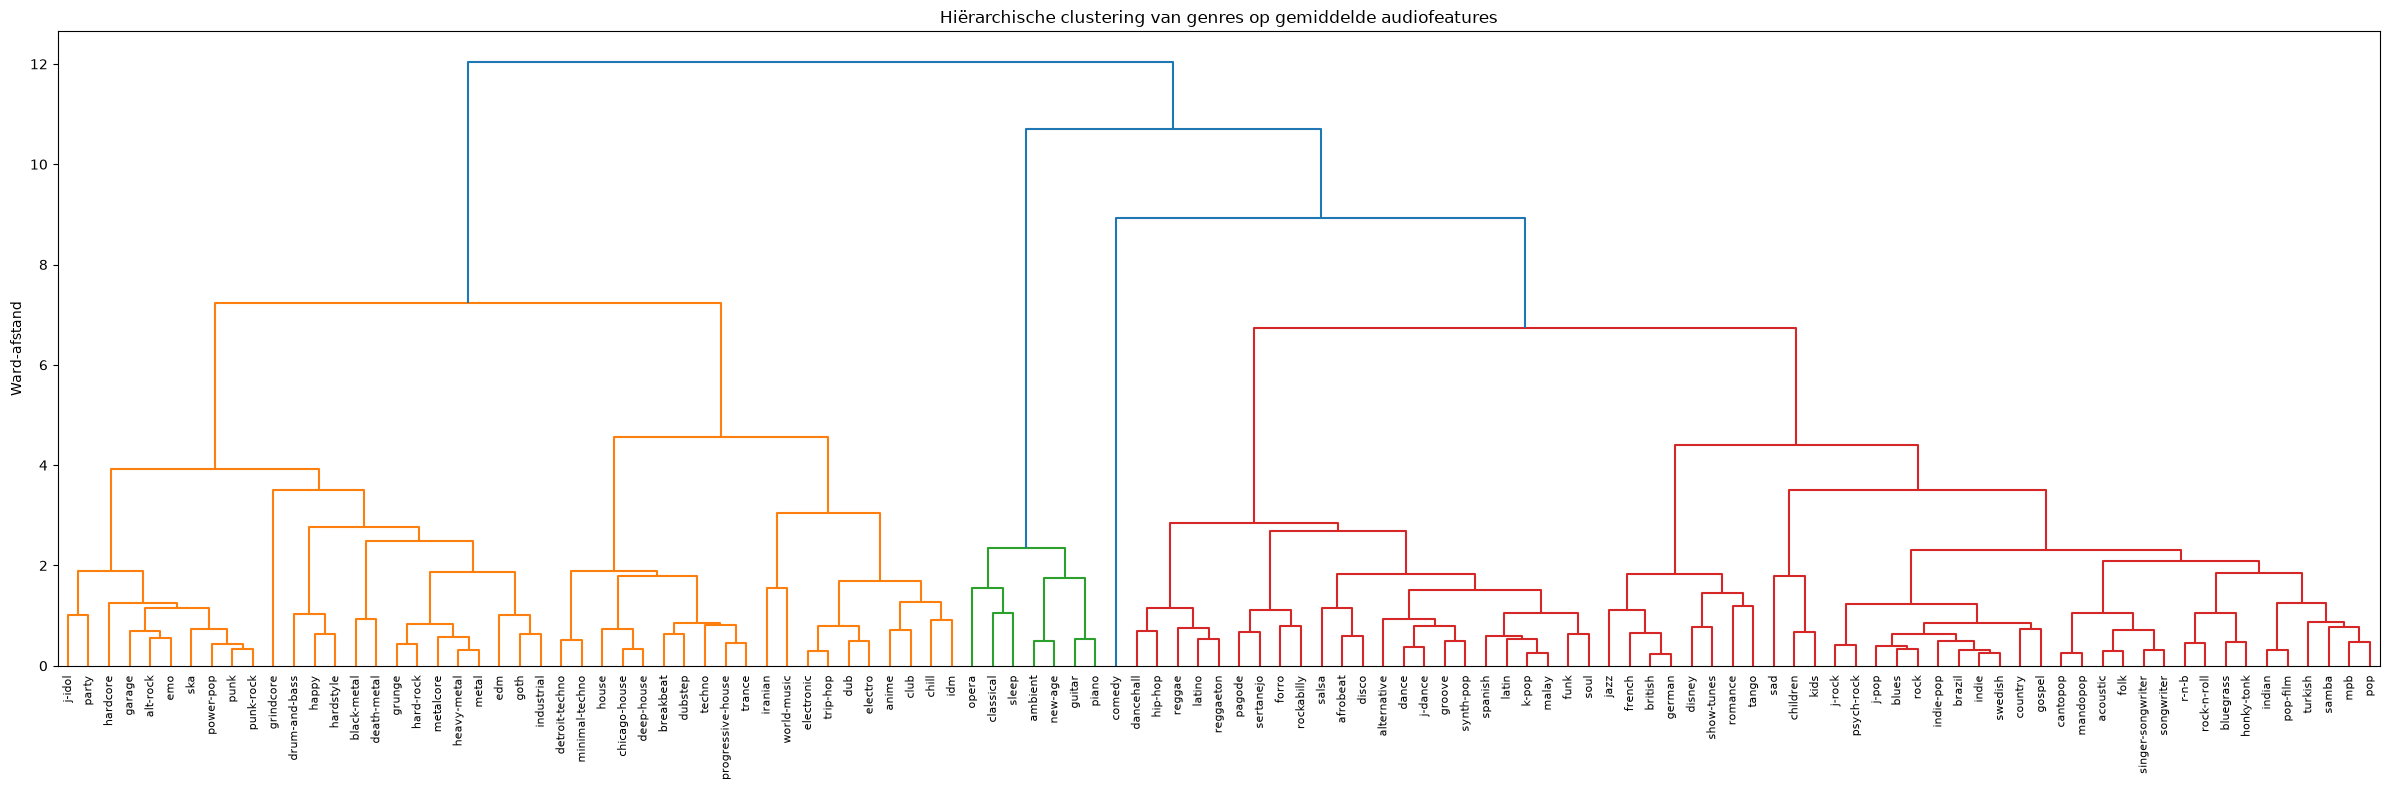

In [143]:

feat = ["acousticness", "danceability", "energy", "instrumentalness", "liveness",
        "loudness", "speechiness", "tempo", "valence", "mode", "duration_seconds"]

X = df[feat].copy()
X["duration_seconds"] = np.log1p(X["duration_seconds"])

X = pd.DataFrame(StandardScaler().fit_transform(X), columns=feat, index=df.index)

profiel = X.groupby(df["genre"]).mean()

Z = linkage(profiel.values, method="ward")

plt.figure(figsize=(24, 8))
dendrogram(Z, labels=profiel.index.tolist(),
           leaf_font_size=8, leaf_rotation=90,
           color_threshold=0.7 * Z[:, 2].max())
plt.title("Hiërarchische clustering van genres op gemiddelde audiofeatures")
plt.ylabel("Ward-afstand")
plt.tight_layout()
plt.show()


In [144]:
VAST = [
    ["indian", "pop-film", "iranian", "turkish", "malay", "world-music"],
    ["comedy"],
]
vast_genres = [g for lijst in VAST for g in lijst]

profiel_rest = profiel.drop(index=vast_genres)
Z_rest = linkage(profiel_rest.values, method="ward")

def groepen_uit_dendrogram(n_groepen):
    labels = fcluster(Z_rest, t=n_groepen - len(VAST), criterion="maxclust")
    clusters = pd.Series(profiel_rest.index, index=labels).groupby(level=0).apply(list)

    groepen = {nr: sorted(leden, key=lambda g: -genre_counts[g]) for nr, leden in clusters.items()}
    for i, leden in enumerate(VAST, start=len(clusters) + 1):
        groepen[i] = leden
    return groepen

NAMEN_14 = {
    1: "punk-alternative",
    2: "fast-electronic",
    3: "metal",
    4: "grindcore",
    5: "house-techno",
    6: "electronic-dance",
    7: "classical-ambient",
    8: "hiphop-reggae",
    9: "latin-disco",
    10: "vintage-vocal",
    11: "kids",
    12: "pop-mix",
    13: "world",
    14: "comedy",
}

NAMEN_21 = {
    1: "punk-alternative",
    2: "fast-electronic",
    3: "metal",
    4: "extreme-metal",
    5: "grindcore",
    6: "minimal-techno",
    7: "house-trance",
    8: "electronic-chill",
    9: "synth-dance",
    10: "classical",
    11: "ambient-piano",
    12: "hiphop-reggae",
    13: "brazilian",
    14: "disco-salsa",
    15: "vintage-vocal",
    16: "kids",
    17: "pop-mix",
    18: "folk-acoustic",
    19: "roots-pop",
    20: "world",
    21: "comedy",
}

def benoem(groepen, namen):
    assert set(groepen) == set(namen), set(groepen) ^ set(namen)
    return {namen[nr]: leden for nr, leden in groepen.items()}

GENRE_GROEPEN_14 = benoem(groepen_uit_dendrogram(14), NAMEN_14)
GENRE_GROEPEN_21 = benoem(groepen_uit_dendrogram(21), NAMEN_21)

for naam, groepen in [("14", GENRE_GROEPEN_14), ("21", GENRE_GROEPEN_21)]:
    print(f"--- {naam} groepen ---")
    for g, leden in groepen.items():
        print(f"{g:20s} ({len(leden):2d}): {', '.join(leden)}")


--- 14 groepen ---
punk-alternative     (10): alt-rock, hardcore, garage, emo, power-pop, ska, punk, j-idol, punk-rock, party
fast-electronic      ( 3): drum-and-bass, happy, hardstyle
metal                ( 7): black-metal, death-metal, hard-rock, heavy-metal, grunge, metal, metalcore
grindcore            ( 1): grindcore
house-techno         (10): deep-house, minimal-techno, trance, breakbeat, house, progressive-house, techno, chicago-house, dubstep, detroit-techno
electronic-dance     (16): dance, dub, anime, electro, goth, chill, industrial, idm, groove, club, synth-pop, edm, trip-hop, electronic, alternative, j-dance
classical-ambient    ( 7): classical, opera, ambient, guitar, new-age, piano, sleep
hiphop-reggae        ( 5): dancehall, hip-hop, reggae, latino, reggaeton
latin-disco          ( 7): disco, forro, salsa, sertanejo, pagode, afrobeat, rockabilly
vintage-vocal        ( 8): german, french, british, jazz, tango, show-tunes, romance, disney
kids                 ( 3): childr

In [145]:
INDELINGEN = {
    "21": GENRE_GROEPEN_21,
    "14": GENRE_GROEPEN_14,
}

def maak_mapping(groepen):
    return {g: groep for groep, genres in groepen.items() for g in genres}

for naam, groepen in INDELINGEN.items():
    mapping = maak_mapping(groepen)
    for d in (train_df, val_df, test_df):
        d[f"groep_{naam}"] = d["genre"].map(mapping)
    snelle_test(f"groep_{naam}")

21 klassen: accuracy 0.400, macro F1 0.410
14 klassen: accuracy 0.510, macro F1 0.487


**Conclusie**

We vergelijken drie indelingen met hetzelfde gradient-boostingmodel, getraind op 100000 trainnummers en geëvalueerd op 100000 validatienummers. Alle indelingen gebruiken dezelfde nummers en alle 113 genres.

| Indeling | Accuracy | Macro-F1 | Willekeurig gokken |
|---|---|---|---|
| 113 originele genres | 15,2% | 0,128 | 0,9% |
| 21 genrefamilies | 40% | 0,410 | 4,8% |
| 14 genrefamilies | 51% | 0,487 | 7,1% |

Met alle 113 genres voorspelt het model 85% van de nummers verkeerd: veel genres overlappen te sterk om ze op basis van audiofeatures te onderscheiden. Door genres samen te voegen tot families stijgt de score duidelijk.

De families komen uit de hiërarchische clustering: elk genre komt in de familie waarop het gemiddelde klankprofiel het meest lijkt. Twee families leggen we vooraf vast. Regionale muziek (indian, turkish, iranian, malay, pop-film, world-music) wordt samengenomen in world, en comedy wordt een aparte familie, omdat gesproken woord geen muziekstijl is.

Labels die een stemming, taal of doelgroep aanduiden, belanden bij de familie die toevallig het meest op hun klank lijkt. Zo komt sad bij kids, komen french, german, british en disney bij vintage-vocal, en zitten spanish, swedish, k-pop en mandopop in pop-mix. Daardoor zijn sommige families eerder een verzameling van gelijkaardig klinkende genres dan een herkenbare muziekstijl.

Hoe fijner de indeling, hoe lager de score. De 21 families geven gedetailleerdere labels, maar kosten 11 procentpunt accuracy en 0,077 macro F1. We kiezen daarom voor 14 genrefamilies.

**Opmerking over leakage:** De genreprofielen voor de clustering zijn berekend op de volledige dataset, inclusief validatie- en testdata. Dit beïnvloedt de indeling in families, maar de impact is klein: het gaat om gemiddelden over duizenden nummers per genre, en het model zelf ziet nooit testdata. Omdat dit pas op het einde van het project ontdekt werd, hebben we de clustering niet opnieuw uitgevoerd. Dat zou alle resultaten licht veranderen.

In [146]:
# Keuze: 14 genrefamilies
mapping_14 = maak_mapping(GENRE_GROEPEN_14)
for d in (train_df, val_df, test_df):
    d["genre_groep"] = d["genre"].map(mapping_14)
    d.drop(columns=["groep_21", "groep_14"], inplace=True, errors="ignore")
    assert d["genre_groep"].notna().all(), "niet elk genre zit in een familie"

KLASSEN = list(GENRE_GROEPEN_14)

# 4. Verdiepende EDA

Deze analyse doen we enkel op de trainset. Zo laten inzichten uit de validatie- en testdata onze keuzes niet beïnvloeden. Voor de grafieken gebruiken we een steekproef van 200000 nummers, dat is ruim genoeg voor de vorm van de verdelingen.

## 4.1 Histogrammen per feature

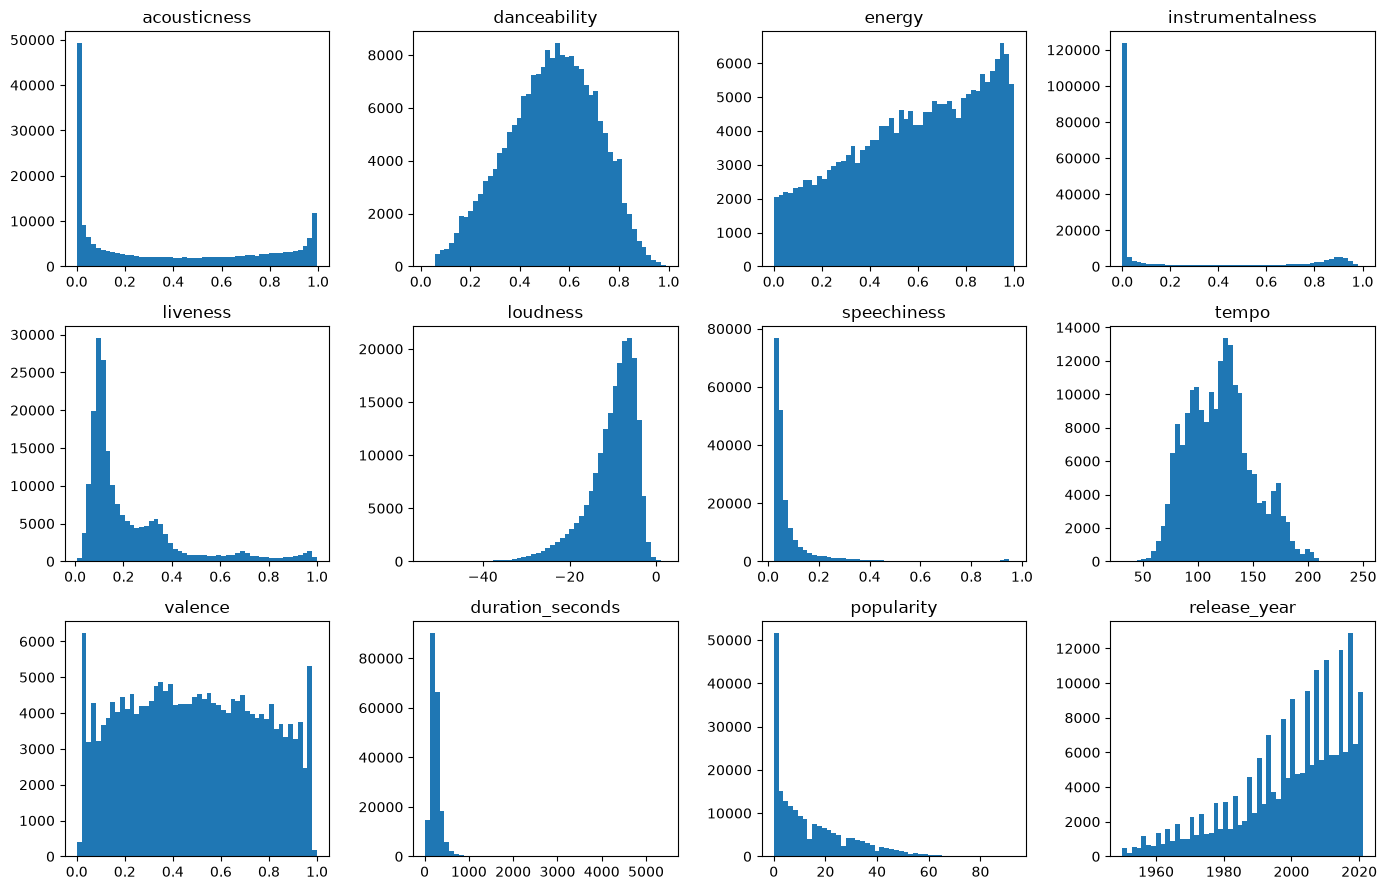

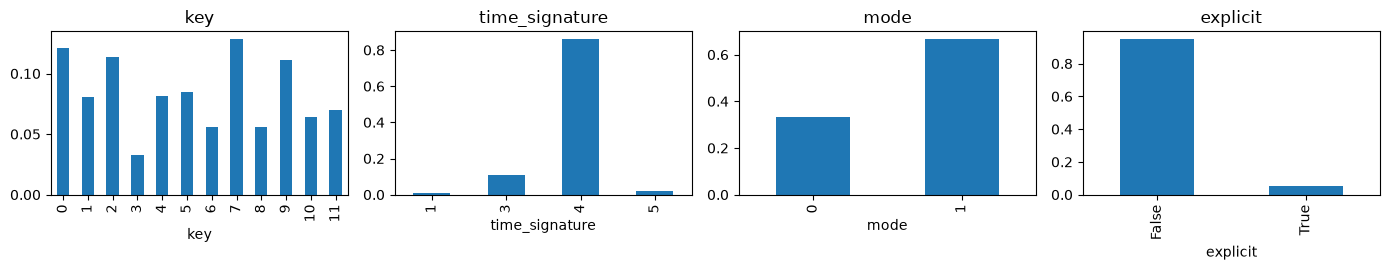

In [147]:
NUM = ["acousticness", "danceability", "energy", "instrumentalness", "liveness", "loudness",
       "speechiness", "tempo", "valence", "duration_seconds", "popularity", "release_year"]
CAT = ["key", "time_signature"]
BIN = ["mode", "explicit"]

eda = train_df.sample(200000, random_state=RANDOM_STATE)
axes = eda[NUM].hist(bins=50, figsize=(14, 9), layout=(3, 4))
for ax in axes.flat:
    ax.grid(False)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, col in zip(axes, CAT + BIN):
    eda[col].value_counts(normalize=True).sort_index().plot.bar(ax=ax, title=col)
plt.tight_layout(); plt.show()

**Conclusie**

* **`acousticness`** heeft een grote piek bij 0 en een kleinere bij 1. Een nummer is vaak duidelijk elektronisch of duidelijk akoestisch. 
* **`danceability`** is ongeveer normaal verdeeld rond 0,55, met weinig extremen.
* **`energy`** loopt lineair op richting 1.
* **`instrumentalness`** heeft een grote piek bij 0 en een kleine rond 0,9. Het is waarschijnlijk sterk om bv. classical en ambient te herkennen.
* **`speechiness`, `liveness` en `popularity`** liggen meestal laag. Het kleine bultje bij `speechiness` rond 0,95 is waarschijnlijk gesproken woord (comedy).
* **`loudness`** piekt rond −7 dB, met een staart naar stille muziek (classical, ambient).
* **`tempo`** heeft pieken rond 95, 125 en 170 BPM, typisch voor verschillende stijlen.
* **`valence`** is vrij gelijkmatig verdeeld tussen 0 en 1. Bij de uiteinden zijn er twee pieken.
* **`duration_seconds`** heeft een zeer lange staart. Voor logistische regressie en k-NN kan een log-transformatie dit bruikbaarder maken.
* **`release_year`** stijgt sterk: er zijn veel meer recente nummers.
* **`explicit`** is zeldzaam (5%), maar kan helpen bij hiphop en comedy.
* **`time_signature`** is bijna altijd 4/4 (ongeveer 86%).
* **`mode`** geeft aan of een nummer in majeur (65%) of mineur (35%) staat. De feature kan helpen bij bv. metal of classical, maar dat zie je pas in het profiel per genrefamilie.
* **`key`** is een getal van 0 tot 11 dat de toonaard aanduidt (0 = C, 1 = C#, ...). Voor logistische regressie en k-NN moeten we het omzetten met one-hot encoding.
* **Gevolg:** de features hebben heel verschillende schalen. Logistische regressie en k-NN hebben daarom standaardisatie nodig.

## 4.2 Profiel per genrefamilie

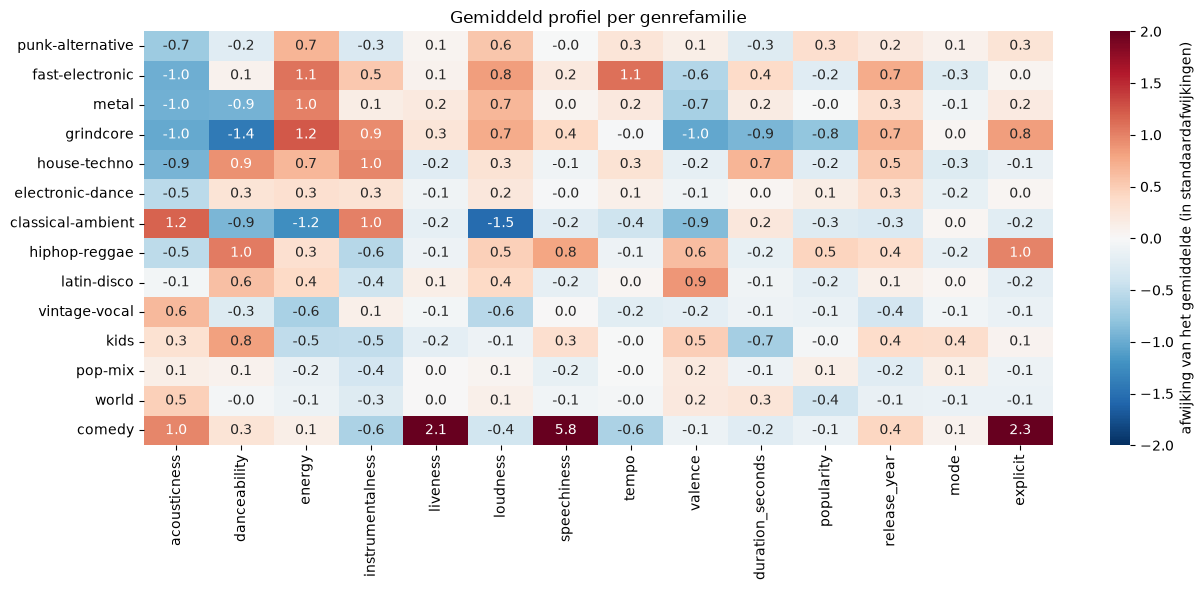

In [148]:
profiel = eda.groupby("genre_groep")[NUM + ["mode", "explicit"]].mean().loc[KLASSEN]
z = (profiel - eda[NUM + ["mode", "explicit"]].mean()) / eda[NUM + ["mode", "explicit"]].std()

fig, ax = plt.subplots(figsize=(13, 6))
sn.heatmap(z, cmap="RdBu_r", center=0, vmin=-2, vmax=2, annot=True, fmt=".1f", ax=ax,
           cbar_kws={"label": "afwijking van het gemiddelde (in standaardafwijkingen)"})
ax.set(title="Gemiddeld profiel per genrefamilie", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

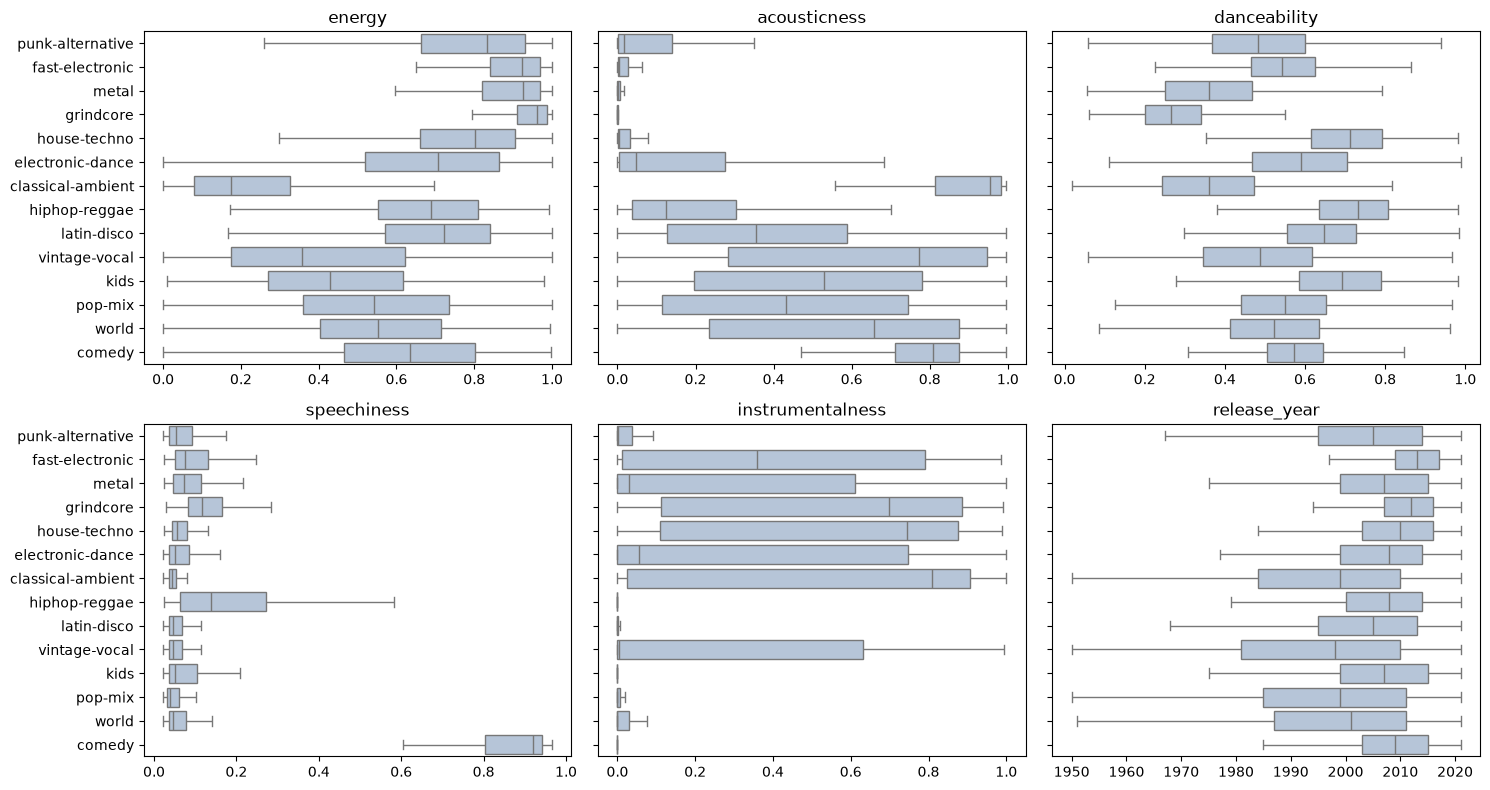

In [149]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, col in zip(axes.flat, ["energy", "acousticness", "danceability", "speechiness", "instrumentalness", "release_year"]):
    sn.boxplot(data=eda, y="genre_groep", x=col, order=KLASSEN, showfliers=False, ax=ax, color="lightsteelblue")
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout(); plt.show()

**Conclusie**

De heatmap en boxplots tonen welke families goed te onderscheiden zijn en welke niet:

* **Duidelijke profielen:** comedy (veel spraak, vaak live en expliciet), classical-ambient (akoestisch, instrumentaal en stil), metal en grindcore (luid, energiek en weinig dansbaar) en house-techno (instrumentaal en dansbaar).
* **Matig herkenbaar:** hiphop-reggae (dansbaar, veel spraak en vaak expliciet), latin-disco (vrolijk en dansbaar) en kids (dansbaar en kort).
* **Overlappend:** pop-mix, electronic-dance en world liggen dicht bij het gemiddelde, en vintage-vocal lijkt op een afgezwakte versie van classical-ambient. Hier zal waarschijnlijk de meeste verwarring zijn.
* **`release_year`** helpt ook: vintage-vocal, classical-ambient en pop-mix zijn ouder, fast-electronic, grindcore en house-techno recenter.

## 4.3 Correlatiematrix

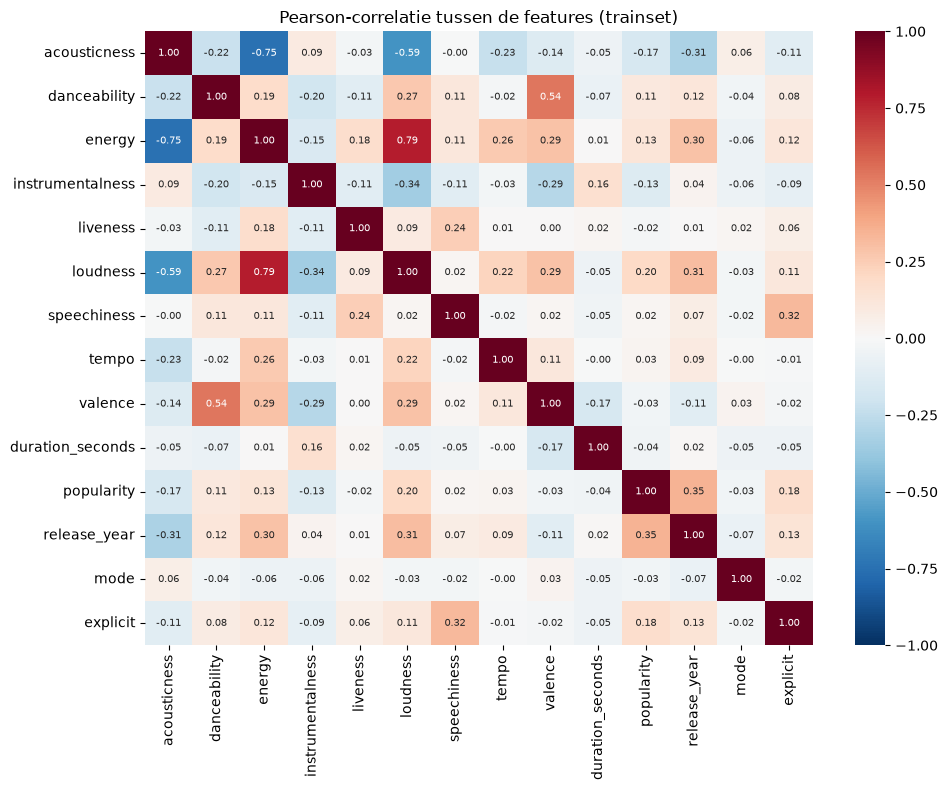

In [150]:
fig, ax = plt.subplots(figsize=(10, 8))
sn.heatmap(eda[NUM + ["mode", "explicit"]].astype(float).corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
           annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set(title="Pearson-correlatie tussen de features (trainset)")
plt.tight_layout(); plt.show()

**Conclusie**

`energy`, `loudness` en `acousticness` zijn sterk gecorreleerd (0,59 tot 0,79 in absolute waarde): luide nummers zijn vaak energiek en niet akoestisch. 
`danceability` en `valence` hangen ook samen (0,54), en daarnaast zijn er verschillende zwakkere correlaties rond 0,3. Deze features bevatten dus deels dezelfde informatie.


Geen enkele correlatie is hoger dan 0,9, dus we laten geen features vallen.

# 5. Preprocessing


In [151]:
for d in (train_df, val_df, test_df):
    d["log_duration"] = np.log(d["duration_seconds"])
    d["explicit"] = d["explicit"].astype(int)

NUM = ["acousticness", "danceability", "energy", "instrumentalness", "liveness", "loudness",
       "speechiness", "tempo", "valence", "log_duration", "popularity", "release_year"]
CAT = ["key", "time_signature"]
BIN = ["mode", "explicit"]

FEATURES = NUM + CAT + BIN
TARGET = "genre_groep"

def lineaire_prep(features=FEATURES):
    return ColumnTransformer([
        ("num", StandardScaler(), [f for f in features if f in NUM]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), [f for f in features if f in CAT]),
    ], remainder="passthrough")

X_train, y_train, g_train = train_df[FEATURES], train_df[TARGET], train_df["artist_name"]
X_val, y_val = val_df[FEATURES], val_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
print(X_train.shape, X_val.shape, X_test.shape)

(1254895, 16) (424181, 16) (418524, 16)


`duration_seconds` wordt omgezet naar een logaritme `log_duration` omdat het een zeer lange staart heeft. 
`explicit` zetten we om van een bool naar een int. 
Dit gebeurt op alle drie de splits op dezelfde manier.

**Preprocessing voor lineaire modellen en k-NN.** Logistische regressie en k-NN zijn gevoelig voor de schaal en de codering van features. Daarom:
* worden numerieke features (NUM) gestandaardiseerd (gemiddelde 0, standaardafwijking 1);
* worden categorische features (CAT) one-hot gecodeerd, zodat bv. toonaard 11 niet als "meer" dan toonaard 0 geldt;
* gaan binaire features (BIN) ongewijzigd door.

Deze stappen zitten in een pipeline en worden alleen op de trainset gefit, zodat validatie en test geen invloed hebben. 
Boommodellen hebben geen schaling nodig en krijgen de ruwe features.

# 6. Modellen en hyperparameter tuning


In [152]:
tune_df = train_df.sample(300000, random_state=RANDOM_STATE)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

modellen = {
    "Logistische regressie": {
        "model": Pipeline([("prep", lineaire_prep()), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        "n_jobs": 3,
        "n_rijen": 300000,
    },
    "k-NN": {
        "model": Pipeline([("prep", lineaire_prep()), ("clf", KNeighborsClassifier(n_neighbors=30, weights="distance", n_jobs=-1))]),
        "n_jobs": 1,
        "n_rijen": 150000,
    },
    "Random forest": {
        "model": RandomForestClassifier(n_estimators=200, max_samples=0.5, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
        "n_jobs": 1,
        "n_rijen": 300000,
    },
    "Gradient boosting": {
        "model": HistGradientBoostingClassifier(max_iter=300, early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE),
        "n_jobs": 1,
        "n_rijen": 300000,
    },
}

basis_scores = {}
for naam, k in modellen.items():
    start = time.time()
    data = tune_df.sample(k["n_rijen"], random_state=RANDOM_STATE)

    res = cross_validate(k["model"], data[FEATURES], data[TARGET], groups=data["artist_name"],
                         cv=cv, scoring=["f1_macro", "accuracy"], n_jobs=k["n_jobs"])

    basis_scores[naam] = res["test_f1_macro"]
    print(f"{naam:22s} macro F1 = {res['test_f1_macro'].mean():.3f} ± {res['test_f1_macro'].std():.3f}  "
          f"accuracy = {res['test_accuracy'].mean():.3f}  ({time.time() - start:.0f} s)")


Logistische regressie  macro F1 = 0.380 ± 0.004  accuracy = 0.354  (21 s)
k-NN                   macro F1 = 0.446 ± 0.004  accuracy = 0.480  (18 s)
Random forest          macro F1 = 0.506 ± 0.005  accuracy = 0.489  (42 s)
Gradient boosting      macro F1 = 0.495 ± 0.007  accuracy = 0.519  (34 s)


In [153]:
ruimtes = {
    "Logistische regressie": {
        "ruimte": {
            "clf__C": loguniform(0.001, 100),
        },
        "n_iter": 8,
    },
    "k-NN": {
        "ruimte": {
            "clf__n_neighbors": randint(5, 150),
            "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2],
        },
        "n_iter": 10,
    },
    "Random forest": {
        "ruimte": {
            "max_depth": [10, 20, 30, None],
            "min_samples_leaf": randint(1, 30),
            "max_features": ["sqrt", 0.5],
            "class_weight": [None, "balanced_subsample"],
        },
        "n_iter": 10,
    },
    "Gradient boosting": {
        "ruimte": {
            "learning_rate": loguniform(0.1, 0.3),
            "max_leaf_nodes": randint(15, 128),
            "min_samples_leaf": randint(20, 300),
            "l2_regularization": loguniform(0.001, 10),
            "class_weight": [None, "balanced"],
        },
        "n_iter": 10,
    },
}

zoektochten = {}
for naam, r in ruimtes.items():
    k = modellen[naam]
    start = time.time()
    data = tune_df.sample(k["n_rijen"], random_state=RANDOM_STATE)

    zoek = RandomizedSearchCV(k["model"], r["ruimte"], n_iter=r["n_iter"], cv=cv,
                              scoring="f1_macro", n_jobs=k["n_jobs"], random_state=RANDOM_STATE)
    zoek.fit(data[FEATURES], data[TARGET], groups=data["artist_name"])

    zoektochten[naam] = zoek
    winst = zoek.best_score_ - basis_scores[naam].mean()
    print(f"{naam:22s} CV macro F1 = {zoek.best_score_:.3f}  ({winst:+.3f} t.o.v. standaard)  "
          f"({time.time() - start:.0f} s)  {zoek.best_params_}")


Logistische regressie  CV macro F1 = 0.380  (-0.000 t.o.v. standaard)  (76 s)  {'clf__C': np.float64(3.9959722831350617)}
k-NN                   CV macro F1 = 0.447  (+0.001 t.o.v. standaard)  (365 s)  {'clf__n_neighbors': 25, 'clf__p': 1, 'clf__weights': 'distance'}
Random forest          CV macro F1 = 0.506  (+0.000 t.o.v. standaard)  (414 s)  {'class_weight': 'balanced_subsample', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 5}
Gradient boosting      CV macro F1 = 0.523  (+0.028 t.o.v. standaard)  (500 s)  {'class_weight': None, 'l2_regularization': np.float64(2.0816774494442964), 'learning_rate': np.float64(0.13498264884217584), 'max_leaf_nodes': 121, 'min_samples_leaf': 141}


**Conclusie**

We vergelijken vier modellen op een steekproef van 300 000 trainnummers (k-NN: 150 000), met macro F1 als maatstaf.

**Waarom macro F1?** De genrefamilies zijn sterk ongebalanceerd: pop-mix bevat 29% van de nummers, grindcore minder dan 1%. Accuracy wordt daardoor vooral bepaald door de grote families: een model dat altijd pop-mix voorspelt, haalt al 29% accuracy. Macro F1 berekent de F1-score per familie en neemt daar het gemiddelde van, zodat elke familie even zwaar telt. Bovendien combineert F1 precision en recall, zodat een model niet hoog scoort door één familie overal te voorspellen. Accuracy rapporteren we als aanvulling.

| Model | Macro F1 | Accuracy |
|---|---|---|
| Logistische regressie | 0,380 | 35,4% |
| k-NN | 0,446 | 48% |
| Random forest | 0,506 | 48,9% |
| Gradient boosting | 0,495 | 51,9% |

Zonder tuning scoren de boommodellen beter dan logistische regressie en k-NN. Dit was te verwachten omdat de grenzen tussen de genrefamilies niet lineair zijn.

Daarna tunen we alle vier de modellen met een randomized search en 3-voudige gegroepeerde cross-validatie.

| Model | Macro F1 voor tuning | Macro F1 na tuning |
|---|---|---|
| Logistische regressie | 0,380 | 0,380 |
| k-NN | 0,446 | 0,447 |
| Random forest | 0,506 | 0,506 |
| Gradient boosting | 0,495 | 0,523 |

Alleen gradient boosting wint duidelijk door te tunen (+0,028). Bij de andere modellen lagen de standaardinstellingen al dicht bij het optimum:

* **Logistische regressie:** de regularisatiesterkte maakt nauwelijks verschil. Met 300 000 nummers en een beperkt aantal features is er weinig risico op overfitting. Het model blijft beperkt doordat het lineair is.
* **k-NN:** de beste instelling (25 buren, gewogen op afstand) ligt dicht bij de oorspronkelijke 30 buren.
* **Random forest:** de beste combinatie van hyperparameters is vrijwel gelijk aan de instellingen die al gekozen waren.

Ook na tuning blijven logistische regressie en k-NN duidelijk achter. Hun achterstand komt dus door het type model en niet door slecht gekozen hyperparameters.

Gradient boosting is het beste model (0,523) en wordt ons eindmodel. Het verschil met random forest (0,506) is groter dan de spreiding tussen de folds (± 0,005 à 0,007).

# 7. Evaluatie van het beste model

## 7.1 Vergelijking met baselines

In [154]:
def evalueer(model, X, y):
    proba = model.predict_proba(X)
    pred = model.classes_[proba.argmax(axis=1)]
    return {"macro F1": f1_score(y, pred, average="macro"),
            "accuracy": accuracy_score(y, pred),
            "balanced accuracy": balanced_accuracy_score(y, pred),
            "top-3 accuracy": top_k_accuracy_score(y, proba, k=3, labels=model.classes_)}

beste = zoektochten["Gradient boosting"].best_estimator_
data = tune_df.sample(modellen["Gradient boosting"]["n_rijen"], random_state=RANDOM_STATE)

te_evalueren = {
    "Baseline: grootste klasse": DummyClassifier(strategy="most_frequent").fit(data[FEATURES], data[TARGET]),
    "Baseline: willekeurig": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(data[FEATURES], data[TARGET]),
    "Gradient boosting (getuned)": beste,
}

resultaten = {}
for naam, model in te_evalueren.items():
    resultaten[naam] = evalueer(model, X_val, y_val)
    resultaten[naam]["train macro F1"] = f1_score(data[TARGET], model.predict(data[FEATURES]), average="macro")
resultaten = pd.DataFrame(resultaten).T
display(resultaten.round(3))


,macro F1,accuracy,balanced accuracy,top-3 accuracy,train macro F1
Baseline: grootste klasse,0.032,0.294,0.071,0.451,0.033
Baseline: willekeurig,0.072,0.144,0.072,0.300,0.071
Gradient boosting (getuned),0.528,0.524,0.501,0.835,0.737


**Conclusie**

Het getunede gradient-boostingmodel is veel beter dan gokken. 
De macro F1 ligt ruim 7 keer hoger dan bij willekeurig gokken, en in 5 op 6 gevallen zit het juiste genre in de top 3.

De validatiescore (0,528) ligt in lijn met de CV-score (0,523), dus de tuning was niet te optimistisch. 
De trainscore ligt met 0,737 wel duidelijk hoger. Dat wijst op enige overfitting: het model leert deels de artiesten uit de trainset, en die komen in de validatieset niet voor.

## 7.2 Prestaties per genrefamilie

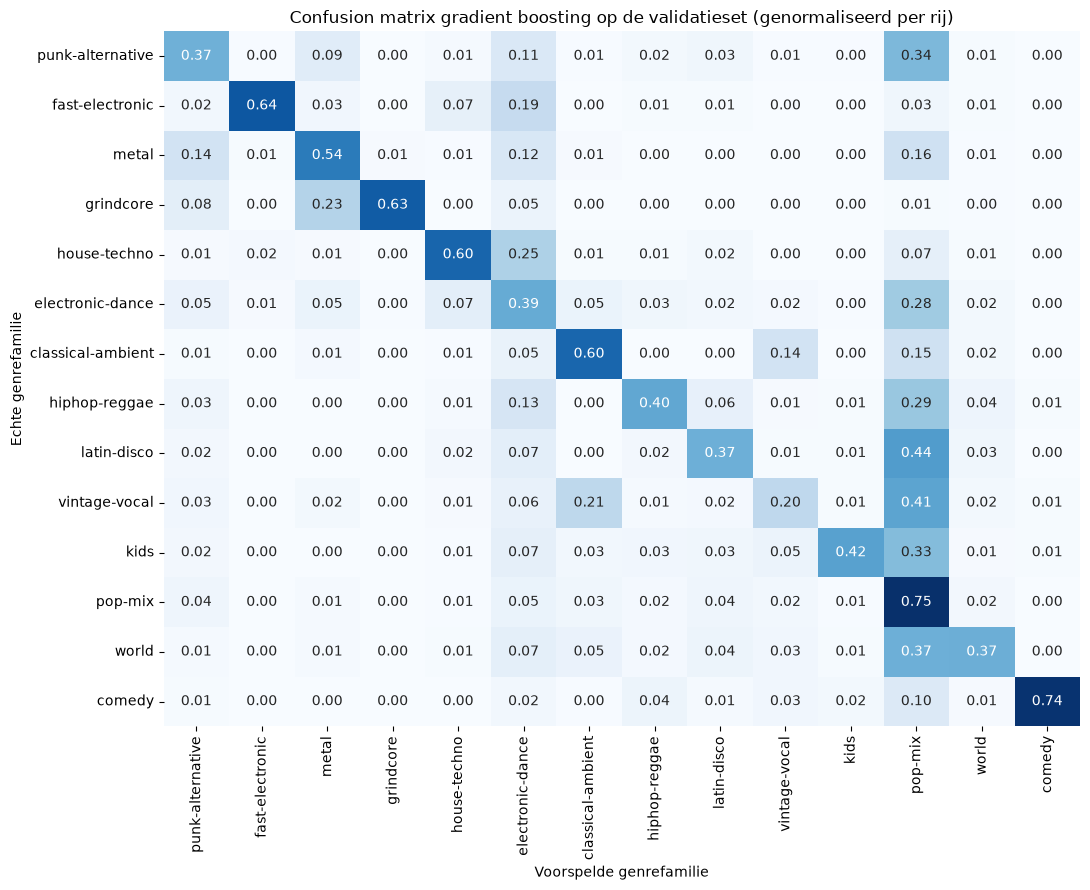

In [155]:
pred_val = beste.predict(X_val)

cm = confusion_matrix(y_val, pred_val, labels=KLASSEN, normalize="true")
fig, ax = plt.subplots(figsize=(11, 9))
sn.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
           xticklabels=KLASSEN, yticklabels=KLASSEN, ax=ax)
ax.set(xlabel="Voorspelde genrefamilie", ylabel="Echte genrefamilie",
       title="Confusion matrix gradient boosting op de validatieset (genormaliseerd per rij)")
plt.tight_layout()
plt.show()

In [156]:
rapport = pd.DataFrame(classification_report(y_val, pred_val, output_dict=True)).T.loc[KLASSEN]
rapport["support"] = rapport["support"].astype(int)
rapport.sort_values("f1-score").round(3)

,precision,recall,f1-score,support
vintage-vocal,0.393,0.205,0.269,39033
electronic-dance,0.415,0.388,0.401,53734
punk-alternative,0.463,0.368,0.410,32954
hiphop-reggae,0.443,0.399,0.420,13005
latin-disco,0.496,0.371,0.425,27902
world,0.584,0.374,0.456,27256
kids,0.555,0.420,0.478,6238
metal,0.526,0.537,0.531,20898
house-techno,0.611,0.599,0.605,19072
classical-ambient,0.618,0.597,0.607,45648


**Conclusie**

Het model herkent vooral de families met een uitgesproken klankprofiel goed, zoals comedy (F1 0,79), grindcore en fast-electronic (allebei 0,69). 
Waar het model zich vergist, is de verwarring meestal muzikaal te verklaren: grindcore wordt bijvoorbeeld als metal voorspeld, en house-techno als electronic-dance.

De grootste foutenbron is pop-mix. 
Die familie heeft een hoge recall (0,75) maar een lage precisie (0,53): bij twijfel kiest het model pop-mix. 
Zo komt 44% van latin-disco en 41% van vintage-vocal bij pop-mix terecht. 
Vintage-vocal wordt daardoor het slechtst herkend, met een recall van amper 0,21.

## 7.3 Wat is het probleem bij pop-mix?

In [157]:
fout = val_df[(pred_val == "pop-mix") & (y_val != "pop-mix")]
naar_pop = (fout["genre"].value_counts() / val_df["genre"].value_counts()).dropna()
naar_pop.sort_values(ascending=False).head(15).round(2)

genre
sertanejo     0.610
reggae        0.580
show-tunes    0.580
dance         0.570
disco         0.570
turkish       0.550
jazz          0.540
alt-rock      0.510
world-music   0.500
synth-pop     0.490
pagode        0.480
british       0.460
punk-rock     0.450
j-dance       0.450
french        0.440
Name: count, dtype: float64

**Conclusie**

Pop-mix is de grootste klasse (29 genres, 29% van de nummers) en heeft een "gemiddeld" klankprofiel. Nummers zonder duidelijk eigen profiel komen daar dus snel terecht.

De genres die het vaakst als pop-mix voorspeld worden, zijn vooral genres die bepaald worden door een taal of regio (sertanejo, pagode, turkish, french, british) of door een tijdperk of sfeer (show-tunes, jazz, disco). Dat zijn eigenschappen die de audiofeatures niet meten. Deze fouten zijn dus eerder een beperking van de features dan van het model.

# 8. Verbeterpogingen

## 8.1 Pop-mix opsplitsen

In [158]:
# Experiment: pop-mix verder opsplitsen
feat_pop = ["acousticness", "danceability", "energy", "instrumentalness", "liveness",
            "loudness", "speechiness", "tempo", "valence", "mode", "duration_seconds"]

X_pop = train_df[feat_pop].copy()
X_pop["duration_seconds"] = np.log1p(X_pop["duration_seconds"])
X_pop = pd.DataFrame(StandardScaler().fit_transform(X_pop), columns=feat_pop, index=train_df.index)
profiel_genre = X_pop.groupby(train_df["genre"]).mean()

pop_genres = GENRE_GROEPEN_14["pop-mix"]
Z_pop = linkage(profiel_genre.loc[pop_genres].values, method="ward")

snelle_test("genre_groep")   # referentie: de huidige 14 groepen

for k in [2, 3, 4]:
    labels = fcluster(Z_pop, t=k, criterion="maxclust")
    groepen = {g: leden for g, leden in GENRE_GROEPEN_14.items() if g != "pop-mix"}
    for nr in range(1, k + 1):
        groepen[f"pop-{nr}"] = [g for g, l in zip(pop_genres, labels) if l == nr]

    kolom = f"groep_pop{k}"
    for d in (train_df, val_df):
        d[kolom] = d["genre"].map(maak_mapping(groepen))

    print(f"\npop-mix in {k} delen:")
    for nr in range(1, k + 1):
        aandeel = (val_df[kolom] == f"pop-{nr}").mean()
        print(f"  pop-{nr} ({aandeel:.0%}): {', '.join(groepen[f'pop-{nr}'])}")
    snelle_test(kolom)

    for d in (train_df, val_df):
        d.drop(columns=kolom, inplace=True)


14 klassen: accuracy 0.510, macro F1 0.487

pop-mix in 2 delen:
  pop-1 (18%): blues, country, brazil, gospel, latin, spanish, funk, k-pop, j-pop, swedish, j-rock, indie, psych-rock, soul, indie-pop, rock
  pop-2 (11%): folk, bluegrass, acoustic, mpb, cantopop, mandopop, pop, rock-n-roll, singer-songwriter, r-n-b, samba, honky-tonk, songwriter
15 klassen: accuracy 0.446, macro F1 0.474

pop-mix in 3 delen:
  pop-1 (18%): blues, country, brazil, gospel, latin, spanish, funk, k-pop, j-pop, swedish, j-rock, indie, psych-rock, soul, indie-pop, rock
  pop-2 (5%): folk, acoustic, cantopop, mandopop, singer-songwriter, songwriter
  pop-3 (6%): bluegrass, mpb, pop, rock-n-roll, r-n-b, samba, honky-tonk
16 klassen: accuracy 0.441, macro F1 0.460

pop-mix in 4 delen:
  pop-1 (5%): latin, funk, k-pop, soul
  pop-2 (13%): blues, country, brazil, gospel, spanish, j-pop, swedish, j-rock, indie, psych-rock, indie-pop, rock
  pop-3 (5%): folk, acoustic, cantopop, mandopop, singer-songwriter, songwrite

**Conclusie**

We knippen pop-mix met hetzelfde soort clustering als bij de genre-groep verdeling op in 2, 3 of 4 delen. 
Dit verlaagt de macro F1 (0,487 → 0,474 tot 0,443) en levert geen herkenbare subgroepen op: de deelgroepen mengen nog steeds genres als country, k-pop en psych-rock.

Het omgekeerde (verwante families samenvoegen met pop-mix) zou de scores wel verhogen, maar dit verhoogt de grootte van deze groep nog verder in verhouding met de andere genres.

## 8.2 Trainen met gebalanceerde klassen

Pop-mix bevat 29% van de nummers, grindcore minder dan 1%. Daardoor kiest het model bij twijfel pop-mix. We testen of gebalanceerd trainen helpt, met dezelfde hyperparameters als in deel 6:

* **A. Huidig:** de oorspronkelijke verdeling.
* **B. Gewogen:** `class_weight="balanced"`, zodat fouten op kleine families zwaarder tellen.
* **C. Evenveel per familie:** evenveel nummers per familie als de kleinste familie heeft.

De validatieset blijft ongebalanceerd, zoals in de werkelijkheid.

In [159]:
# A: het getunede model uit deel 6 (al getraind op tune_df)
huidig = zoektochten["Gradient boosting"].best_estimator_

# C: uit de volledige trainset evenveel nummers per familie als de kleinste familie heeft
kleinste = train_df[TARGET].value_counts().min()
evenveel = train_df.groupby(TARGET).sample(kleinste, random_state=RANDOM_STATE)

varianten = {
    "A. Huidig": huidig,
    "B. Gewogen": clone(huidig).set_params(class_weight="balanced").fit(tune_df[FEATURES], tune_df[TARGET]),
    "C. Evenveel per familie": clone(huidig).fit(evenveel[FEATURES], evenveel[TARGET]),
}

display(pd.DataFrame({naam: evalueer(m, X_val, y_val) for naam, m in varianten.items()}).T.round(3))
display(pd.DataFrame({naam: f1_score(y_val, m.predict(X_val), labels=KLASSEN, average=None)
                      for naam, m in varianten.items()}, index=KLASSEN).sort_values("A. Huidig").round(3))

,macro F1,accuracy,balanced accuracy,top-3 accuracy
A. Huidig,0.528,0.524,0.501,0.835
B. Gewogen,0.496,0.455,0.574,0.801
C. Evenveel per familie,0.460,0.429,0.575,0.775


,A. Huidig,B. Gewogen,C. Evenveel per familie
vintage-vocal,0.269,0.297,0.283
electronic-dance,0.401,0.326,0.290
punk-alternative,0.410,0.408,0.385
hiphop-reggae,0.420,0.394,0.381
latin-disco,0.425,0.418,0.404
world,0.456,0.449,0.439
kids,0.478,0.360,0.312
metal,0.531,0.518,0.496
house-techno,0.605,0.595,0.589
classical-ambient,0.607,0.605,0.588


**Conclusie**

Gebalanceerd trainen maakt het model slechter. De macro F1 daalt van 0,528 naar 0,496 (gewogen) en 0,460 (evenveel per familie), en de accuracy zakt van 52,4% naar 45,5% en 42,9%. 
Alleen de balanced accuracy stijgt, tot ongeveer 0,575.

Het gebalanceerde model voorspelt kleine families vaker, waardoor hun recall stijgt maar hun precisie daalt. Kids zakt daardoor van een F1 van 0,478 naar 0,360, en pop-mix van 0,623 naar 0,468. Alleen vintage-vocal en grindcore winnen een klein beetje. Omdat de validatieset de echte, ongebalanceerde verdeling volgt, zijn die extra gokken op kleine families meestal fout.

Variant C traint bovendien op veel minder nummers (ongeveer 117 000, 14 keer de grootte van de kleinste familie) dan A en B (300 000). Een deel van de daling komt dus door minder trainingsdata, niet alleen door de balancering. Variant B heeft dat probleem niet en scoort toch lager, dus de conclusie blijft dezelfde.


We houden daarom het huidige model als eindmodel.

# 9. Featureselectie

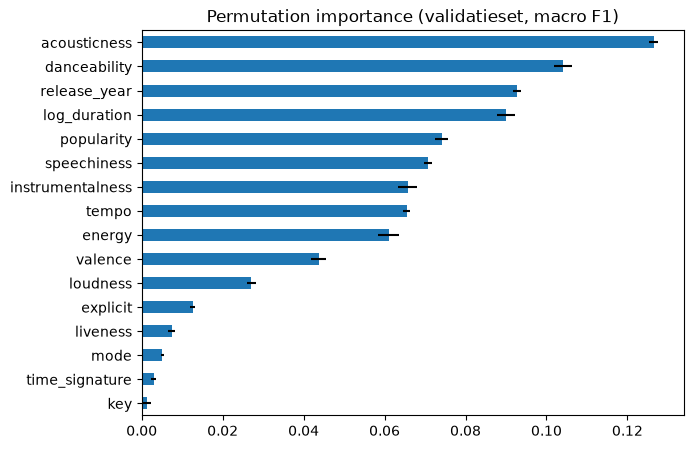

 4 features: macro F1 0.324
 6 features: macro F1 0.435
 8 features: macro F1 0.491
10 features: macro F1 0.515
12 features: macro F1 0.523
16 features: macro F1 0.528
Zonder metadata: 0.471


In [160]:
va = val_df.sample(50000, random_state=RANDOM_STATE)
pi = permutation_importance(huidig, va[FEATURES], va[TARGET], scoring="f1_macro",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(xerr=pd.Series(pi.importances_std, index=FEATURES)[imp.index], figsize=(7, 5))
plt.title("Permutation importance (validatieset, macro F1)"); plt.show()

volgorde = imp.sort_values(ascending=False).index.tolist()
for k in [4, 6, 8, 10, 12, len(FEATURES)]:
    top = volgorde[:k]
    m = clone(huidig).fit(tune_df[top], tune_df[TARGET])
    print(f"{k:2d} features: macro F1 {f1_score(y_val, m.predict(X_val[top]), average='macro'):.3f}")

# Extra: enkel audio, zonder metadata
audio_only = [f for f in FEATURES if f not in ["popularity", "release_year", "explicit"]]
m = clone(huidig).fit(tune_df[audio_only], tune_df[TARGET])
print("Zonder metadata:", round(f1_score(y_val, m.predict(X_val[audio_only]), average="macro"), 3))

**Conclusie**

Acousticness en danceability zijn de belangrijkste features, gevolgd door release_year, log_duration en popularity. 
Key, time_signature, mode en liveness dragen bijna niets bij. Dat bevestigt de EDA: bijna alle nummers staan in 4/4, en toonaard of majeur/mineur zegt weinig over het genre.

Met de 12 belangrijkste features haalt het model een macro F1 van 0,523, tegenover 0,528 met alle 16. 
Dat verschil valt binnen de spreiding van de cross-validatie (± 0,005 à 0,007). 
We kiezen daarom voor 12 features: een eenvoudiger model met dezelfde prestaties. 
De hyperparameters zijn wel getuned op alle 16 features. 
Opnieuw tunen op 12 features kan nog een kleine winst geven.

Een lage permutation importance betekent niet dat een feature op zich niets zegt. Loudness hangt sterk samen met energy en acousticness (zie 4.3). Als loudness door elkaar geschud wordt, haalt het model dezelfde informatie uit de andere twee.

Zonder metadata (popularity, release_year en explicit) daalt de macro F1 naar 0,471. Popularity is echter geen eigenschap van de muziek: een nieuw nummer heeft bij release nog geen populariteit. Voor een toepassing op echt nieuwe nummers is 0,471 dus de realistischere score. Release_year is wel bekend bij release, maar is het jaar van het album en niet altijd van de muziek.

# 10. Eindevaluatie op de testset

In [161]:
GEKOZEN = volgorde[:12]   # de 12 belangrijkste features uit de permutation importance
print("Gebruikte features:", GEKOZEN)

# Model uit deel 7 opnieuw trainen op de 12 features, zodat validatie en test vergelijkbaar zijn
huidig_12 = clone(huidig).fit(tune_df[GEKOZEN], tune_df[TARGET])

eind_df = pd.concat([train_df[GEKOZEN + [TARGET]], val_df[GEKOZEN + [TARGET]]])
start = time.time()
eindmodel = clone(huidig).fit(eind_df[GEKOZEN], eind_df[TARGET])
print(f"Getraind op {len(eind_df):,} nummers ({time.time() - start:.0f} s)")

display(pd.DataFrame({
    "Validatie (12 features)": evalueer(huidig_12, X_val[GEKOZEN], y_val),
    "Test (eindmodel, 12 features)": evalueer(eindmodel, X_test[GEKOZEN], y_test),
}).T.round(3))

pred_test = eindmodel.predict(X_test[GEKOZEN])
rapport_test = pd.DataFrame(classification_report(y_test, pred_test, output_dict=True)).T.loc[KLASSEN]
rapport_test.sort_values("f1-score").round(3)

Gebruikte features: ['acousticness', 'danceability', 'release_year', 'log_duration', 'popularity', 'speechiness', 'instrumentalness', 'tempo', 'energy', 'valence', 'loudness', 'explicit']
Getraind op 1,679,076 nummers (259 s)


,macro F1,accuracy,balanced accuracy,top-3 accuracy
Validatie (12 features),0.523,0.521,0.496,0.832
"Test (eindmodel, 12 features)",0.537,0.540,0.513,0.845


,precision,recall,f1-score,support
vintage-vocal,0.548,0.239,0.333,39034.000
electronic-dance,0.434,0.399,0.416,53737.000
punk-alternative,0.472,0.376,0.419,32955.000
latin-disco,0.525,0.357,0.425,27902.000
kids,0.567,0.359,0.440,6715.000
world,0.610,0.361,0.454,27256.000
hiphop-reggae,0.489,0.444,0.465,13005.000
metal,0.512,0.533,0.522,20899.000
house-techno,0.614,0.624,0.619,19075.000
classical-ambient,0.603,0.661,0.631,39496.000


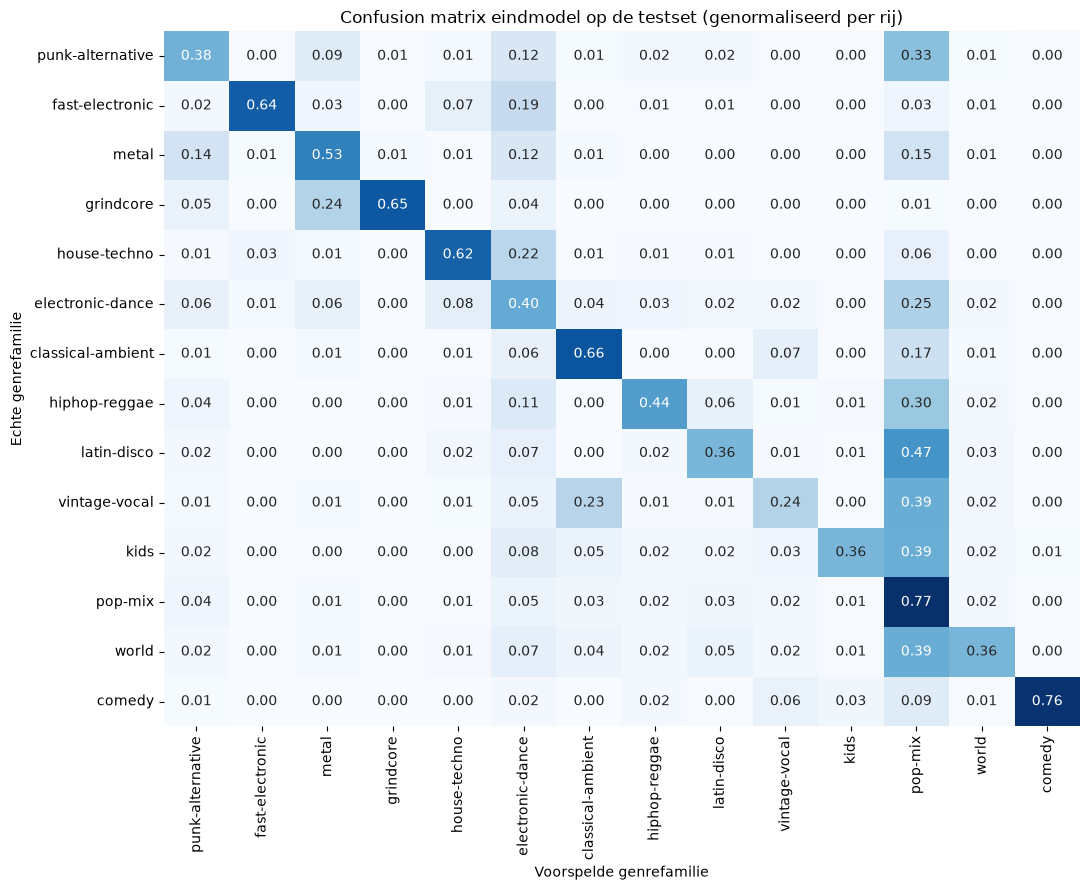

In [162]:
cm = confusion_matrix(y_test, pred_test, labels=KLASSEN, normalize="true")
fig, ax = plt.subplots(figsize=(11, 9))
sn.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
           xticklabels=KLASSEN, yticklabels=KLASSEN, ax=ax)
ax.set(xlabel="Voorspelde genrefamilie", ylabel="Echte genrefamilie",
       title="Confusion matrix eindmodel op de testset (genormaliseerd per rij)")
plt.tight_layout(); plt.show()

**Conclusie**

Het eindmodel gebruikt de 12 gekozen features en is getraind op de train- en validatieset samen. Op de testset haalt het een macro F1 van 0,537 en een accuracy van 54,0%. In 84,5% van de gevallen zit de juiste genrefamilie in de top 3. Willekeurig gokken haalt een macro F1 van 0,072, het model doet het dus ruim 7 keer beter.

De testscore ligt iets hoger dan op de validatieset (0,523), waarschijnlijk omdat het eindmodel op ruim 5 keer zoveel nummers getraind is. Met alle 16 features was de testscore 0,544. Het verlies van 0,007 is even klein als op de validatieset (0,005), dus de keuze voor 12 features houdt stand. Omdat de testset alleen artiesten bevat die het model nooit gezien heeft, is dit een eerlijke schatting voor nieuwe artiesten.

Het patroon is hetzelfde als op de validatieset. Families met een uitgesproken klankprofiel worden het best herkend: comedy (F1 0,82), grindcore (0,69) en fast-electronic (0,66). Vintage-vocal scoort het slechtst (0,33). De precisie is redelijk (0,55), maar het model herkent maar 24% van die nummers.

De meeste fouten zijn muzikaal te verklaren:

* **Pop-mix is de vergaarbak.** Pop-mix heeft de hoogste recall (0,77) maar een lage precisie (0,54). Bij twijfel kiest het model pop-mix: 47% van latin-disco, 39% van vintage-vocal, kids en world, en 33% van punk-alternative komt daar terecht. Die families worden vaak bepaald door taal, regio of tijdperk, en dat meten de audiofeatures niet.
* **Verwarring tussen verwante families.** Grindcore wordt in 24% van de gevallen als metal voorspeld, maar omgekeerd bijna nooit (1%). Grindcore is een extreme vorm van metal, en metal is een veel grotere klasse. House-techno (22%) en fast-electronic (19%) worden vaak als electronic-dance voorspeld. Metal en punk-alternative worden ook onderling verward (14% en 9%).
* **Vintage-vocal wordt vaak als classical-ambient voorspeld (23%).** Oudere vocale muziek zoals jazz, chansons en show-tunes is akoestisch en rustig, en lijkt in de audiofeatures dus op klassieke muziek.
* **Comedy wordt goed herkend (recall 0,76).** De meeste fouten gaan naar pop-mix (9%) en vintage-vocal (6%), waarschijnlijk bij muzikale comedy.

Het model maakt dus zelden fouten tussen families die echt verschillend klinken. Zo wordt classical-ambient bijna nooit als metal voorspeld. De meeste fouten liggen tussen muzikale buren of komen in pop-mix terecht. Dat is vooral een beperking van de features en van de labels, die soms taal, regio of doelpubliek beschrijven in plaats van een klank. Het model zelf schiet daar minder tekort.

# 11. Eindconclusie

**Welke problemen vonden we in de dataset?**
* **Groepering op artiest:** 89% van de nummers heeft het meest voorkomende genre van hun artiest. Een willekeurige split laat het model de artiest herkennen in plaats van het genre.
* **Gesorteerde data:** de rijen staan op releasejaar en genre gesorteerd, dus splitsen op positie is nooit toegestaan.
* **Duplicaten:** 1,3% van de rijen is dezelfde opname onder een andere titel of artiest, soms met een ander genre. We hielden enkel de eerste kopie (15 066 rijen verwijderd).
* **Onmogelijke en ontbrekende waarden:** tempo of time_signature gelijk aan 0, en nummers zonder artiest (80 rijen verwijderd).
* **Onbetrouwbare datums:** gemengde formaten en veel datums op 1 januari, dus we houden enkel het jaar.
* **Labels:** veel van de 113 genres zijn geen muziekstijl maar een taal, stemming of doelgroep, en 12% van de albums heeft gemengde genres. Dat is labelruis die de haalbare score beperkt.

**Hoe splitsten we de data en waarom?**
60% train, 20% validatie en 20% test met `StratifiedGroupKFold`: gegroepeerd op `artist_name`, zodat geen artiest in twee splits zit, en gestratificeerd op genre, zodat elke split dezelfde verdeling heeft. Tuning gebeurde met 3-voudige gegroepeerde cross-validatie op de trainset. De validatieset diende voor keuzes, de testset werd pas op het einde één keer gebruikt.

**Welke features en welke preprocessing?**
De 12 belangrijkste features volgens permutation importance: acousticness, danceability, release_year, log_duration, popularity, speechiness, instrumentalness, tempo, energy, valence, loudness en explicit. Key, mode, time_signature en liveness lieten we vallen, omdat ze bijna niets bijdroegen. De duur zetten we om naar een logaritme. Voor logistische regressie en k-NN standaardiseren we de numerieke features en coderen we de categorische features met one-hot encoding. Boommodellen krijgen de ruwe waarden. Het doelveld is gegroepeerd van 113 genres naar 14 genrefamilies via hiërarchische clustering op het klankprofiel.

**Welke modellen en waarom?**
Vier modellen uit verschillende families: logistische regressie (lineaire baseline), k-NN (afstandsgebaseerd), random forest en gradient boosting (niet-lineaire boommodellen). Gradient boosting scoorde na tuning het best (CV macro F1 0,523) en is het eindmodel.

**Welke performance en waarom deze metriek?**
Op de testset: macro F1 0,537, accuracy 54,0% en top-3 accuracy 84,5%. We gebruiken macro F1 omdat de families ongelijk verdeeld zijn: elke familie telt even zwaar, en precision en recall worden allebei meegenomen.

**Is dit een goede performance?**
Het model is ruim 7 keer beter dan willekeurig gokken (macro F1 0,072), en in 5 op 6 gevallen zit de juiste familie in de top 3. Families met een eigen klankprofiel worden goed herkend: comedy (0,82), grindcore (0,69) en fast-electronic (0,66). De meeste fouten zijn muzikaal verklaarbaar of komen in pop-mix terecht, de vergaarbak met een gemiddeld profiel. Taal, regio en tijdperk zitten niet in de audiofeatures, en het genre hoort vaak bij de artiest en niet bij het nummer. Een veel hogere score is met deze features dus niet realistisch. Zonder metadata (popularity, release_year en explicit) daalt de score naar 0,471. Dat is de realistische score voor een nummer dat net uitgebracht is.

**Beperkingen en mogelijke verbeteringen**
* De genreclustering gebeurde op de volledige dataset in plaats van enkel op de trainset (zie 3.3).
* Tuning gebeurde op een steekproef van 300 000 nummers en met de 16 features, niet met de 12 gekozen features.
* `track_name` en `album_name` bleven ongebruikt. Tekstfeatures, zoals de taal van de titel, kunnen helpen voor families als world en vintage-vocal.